<a href="https://colab.research.google.com/github/kavy988/Research-Paper-Implementation/blob/main/Research_paper.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 08. PyTorch Paper Replicating

In this project, we're going to be replicating a machine learning research paper and creating a Vision Transformer (ViT) from scratch using PyTorch.

We'll then see how ViT, a state-of-the-art computer vision architecture, performs on our FoodVision Mini problem

* What is paper replicating?

* It's no secret machine learning is advancing fast.

* Many of these advances get published in machine learning research papers.

* And the goal of paper replicating is to replicate these advances with code so you can use the techniques for your own problem.

* For example, let's say a new model architecture gets released that performs better than any other architecture before on various benchmarks, wouldn't it be nice to try that architecture on your own problems?

What is paper replicating?

It's no secret machine learning is advancing fast.

* Many of these advances get published in machine learning research papers.

* And the goal of paper replicating is to replicate these advances with code so you can use the techniques for your own problem.

[ For example, let's say a new model architecture gets released that performs better than any other architecture before on various benchmarks, wouldn't it be nice to try that architecture on your own problems? ]

* More specifically, we're going to be replicating the machine learning research paper An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale (ViT paper) with PyTorch.

* the Transformer neural network architecture was originally introduced in the machine learning research paper Attention is all you need.

* And the original Transformer architecture was designed to work on one-dimensional (1D) sequences of text.

* A Transformer architecture is generally considered to be any neural network that uses the (attention mechanism) as its primary learning layer. Similar to how a convolutional neural network (CNN) uses convolutions as its primary learning layer.

* Like the name suggests, the Vision Transformer (ViT) architecture was designed to adapt the original Transformer architecture to vision problem(s) (classification being the first and since many others have followed).

* The original Vision Transformer has been through several iterations over the past couple of years, however, we're going to focus on replicating the original, otherwise known as the "vanilla Vision Transformer". Because if you can recreate the original, you can adapt to the others.

#### Terminology

* ViT - Stands for Vision Transformer (the main neural network architecture we're going to be focused on replicating).

* ViT paper - Short hand for the original machine learning research paper that introduced the ViT architecture, An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale, anytime ViT paper is mentioned, you can be assured it is referencing this paper.

# 0. Getting setup

In [ ]:
import torch
import torchvision

print(torch.__version__)
print(torchvision.__version__)

2.11.0+cu128
0.26.0+cu128


In [ ]:
import matplotlib.pyplot as plt
from torch import nn

from torchvision import transforms

try :
  from torchinfo import summary
except :
  print(f"Couldn't find torchinfo..... installing it .")
  !pip install -q torchinfo
  from torchinfo import summary


Couldn't find torchinfo..... installing it .


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys
sys.path.append('/content/drive/MyDrive')
from going_modular.going_modular import data_setup, engine
from helper_functions import download_data, set_seeds, plot_loss_curves

Mounted at /content/drive


In [ ]:
device = "cuda" if torch.cuda.is_available else "cpu"
device

'cuda'

# 1. Get Data

In [ ]:
# # download pizza , steak , sushi images from github
image_path = download_data(source = "https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip",
                           destination = "pizza_steak_sushi")
image_path

[INFO] Did not find data/pizza_steak_sushi directory, creating one...
[INFO] Downloading pizza_steak_sushi.zip from https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip...
[INFO] Unzipping pizza_steak_sushi.zip data...


PosixPath('data/pizza_steak_sushi')

Note :-
* download_data  - Ye ek function hai (method nahi, attribute bhi nahi) — helper_functions.py file ke andar defined hai

Note :-

* Function: standalone, kahin se bhi call karo (download_data(...))

* Method: class ke andar hota, object pe call hota (obj.method())

* Attribute: object/class ka variable/property hota, function nahi

In [ ]:
# setup directory path to train and test images
train_dir = image_path / "train"
test_dir = image_path / "test"

In [ ]:
train_dir ,test_dir

(PosixPath('data/pizza_steak_sushi/train'),
 PosixPath('data/pizza_steak_sushi/test'))

# 2. Create datasets and dataloaders

Now we've got some data, let's now turn it into DataLoader's.

To do so we can use the create_dataloaders() function in data_setup.py.

First, we'll create a transform to prepare our images.

This where one of the first references to the ViT paper will come in.

the training resolution is mentioned as being 224 (height=224, width=224).

### 2. Prepare transforms for images

In [ ]:
# create image size (from table 3 in the Vit Paper)
IMG_SIZE = 224


# create transform pipeline manually
manual_transforms = transforms.Compose([
    transforms.Resize(size = (IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

print(f"manually created transforms : {manual_transforms}")

manually created transforms : Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)


### 2.2 Turn images into DataLoader's

The ViT paper states the use of a batch size of 4096 which is 128x the size of the batch size we've been using (32).

However, we're going to stick with a batch size of 32.

Why?

Because some hardware (including the free tier of Google Colab) may not be able to handle a batch size of 4096.

Having a batch size of 4096 means that 4096 images need to fit into the GPU memory at a time.

This works when you've got the hardware to handle it like a research team from Google often does but when you're running on a single GPU (such as using Google Colab), making sure things work with smaller batch size first is a good idea.

An extension of this project could be to try a higher batch size value and see what happens.



Note:-

[ We're using the pin_memory=True parameter in the create_dataloaders() function to speed up computation. pin_memory=True avoids unnecessary copying of memory between the CPU and GPU memory by "pinning" examples that have been seen before. Though the benefits of this will likely be seen with larger dataset sizes (our FoodVision Mini dataset is quite small). However, setting pin_memory=True doesn't always improve performance (this is another one of those we're scenarios in machine learning where some things work sometimes and don't other times), so best to experiment, experiment, experiment. ]

In [ ]:
# set the batch size
BATCH_SIZE = 32

# create the dataloaders
train_dataloader , test_dataloader , class_names = data_setup.create_dataloaders(
    train_dir = train_dir ,
    test_dir = test_dir ,
    transform = manual_transforms,
    batch_size = BATCH_SIZE
)

train_dataloader , test_dataloader , class_names

(<torch.utils.data.dataloader.DataLoader at 0x78535c4931d0>,
 ['pizza', 'steak', 'sushi'])

### 2.3 Visualize a single image

An important step in the ViT paper is preparing the images into patches.

We'll get to what this means in section 4 but for now, let's view a single image and its label.

To do so, let's get a single image and label from a batch of data and inspect their shapes.

In [ ]:
# get the batch of images

image_batch , label_batch = next(iter(train_dataloader))

# get a single image from the batch
image, label = image_batch[2], label_batch[2]

# view the batch shape
image.shape , label

(torch.Size([3, 224, 224]), tensor(1))

In [ ]:
image


tensor([[[0.5804, 0.5725, 0.5843,  ..., 0.9686, 0.9373, 0.9176],
         [0.5882, 0.6118, 0.6549,  ..., 0.9333, 0.9373, 0.9255],
         [0.7804, 0.8314, 0.8784,  ..., 0.9373, 0.9333, 0.9255],
         ...,
         [0.7765, 0.7765, 0.7804,  ..., 0.8196, 0.8235, 0.8275],
         [0.7804, 0.7804, 0.7804,  ..., 0.8235, 0.8196, 0.8196],
         [0.7843, 0.7725, 0.7765,  ..., 0.8235, 0.8196, 0.8196]],

        [[0.3608, 0.3569, 0.3765,  ..., 0.9137, 0.8824, 0.8627],
         [0.4314, 0.4588, 0.5059,  ..., 0.8784, 0.8824, 0.8667],
         [0.6980, 0.7529, 0.8039,  ..., 0.8824, 0.8745, 0.8667],
         ...,
         [0.7412, 0.7373, 0.7412,  ..., 0.7843, 0.7922, 0.7961],
         [0.7451, 0.7451, 0.7412,  ..., 0.7843, 0.7882, 0.7882],
         [0.7490, 0.7373, 0.7412,  ..., 0.7882, 0.7882, 0.7882]],

        [[0.1451, 0.1412, 0.1765,  ..., 0.7804, 0.7569, 0.7490],
         [0.2510, 0.2863, 0.3451,  ..., 0.7373, 0.7529, 0.7490],
         [0.5686, 0.6235, 0.6824,  ..., 0.7412, 0.7451, 0.

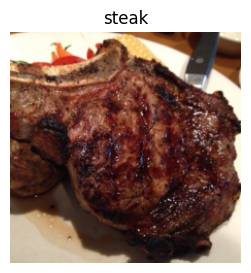

In [ ]:
# now lets plot the image and its label with matplotlib

# plot image with matplotlib.

plt.figure(figsize  = (4,3))
plt.imshow(image.permute(1,2,0)) # rearrange image dimensions to suit matplotlib [color_channels, height, width] -> [height, width, color_channels]
plt.title(class_names[label])
plt.axis(False);

# 3. Replicating the VIT paper : an overview

We'd like to replicate the ViT paper for our own problem, FoodVision Mini.

So our model inputs are: images of pizza, steak and sushi.

And our ideal model outputs are: predicted labels of pizza, steak or sushi.

No different to what we've been doing throughout the previous sections.

The question is: how do we go from our inputs to the desired outputs?

### 3.1 Inputs and Outputs , layers and blocks

ViT is a deep learning neural network architecture.

And any neural network architecture is generally comprised of layers.

And a collection of layers is often referred to as a block.

And stacking many blocks together is what gives us the whole architecture.

A layer takes an input (say an image tensor), performs some kind of function on it (for example what's in the layer's forward() method) and then returns an output.

So if a single layer takes an input and gives an output, then a collection of layers or a block also takes an input and gives an output.

* Layer - takes an input, performs a function on it, returns an output.

* Block - a collection of layers, takes an input, performs a series of functions on it, returns an output.

* Architecture (or model) - a collection of blocks, takes an input, performs a series of functions on it, returns an output.

1. We're going to take it layer by layer, block by block, function by function putting the pieces of the puzzle together like Lego to get our desired overall architecture.

2.  So for a better understanding, we'll break it down, starting with the inputs and outputs of single layer and working up to the inputs and outputs of the whole model.

### 3.2 Getting specific : what's ViT made of ?

The main three resources we'll be looking at for the architecture design are:

* Figure 1 - This gives an overview of the model in a graphical sense, you could almost recreate the architecture with this figure alone.

* Four equations in section 3.1 - These equations give a little bit more of a mathematical grounding to the coloured blocks in Figure 1.

* Table 1 - This table shows the various hyperparameter settings (such as number of layers and number of hidden units) for different ViT model variants. We'll be focused on the smallest version, ViT-Base.


#### 3.2.1 Exploring Figure 1

The main things we'll be paying attention to are:

1. Layers - takes an input, performs an operation or function on the input, produces an output.

2. Blocks - a collection of layers, which in turn also takes an input and produces an output.

The ViT architecture is comprised of several stages:

* Patch + Position Embedding (inputs) - Turns the input image into a sequence of image patches and adds a position number to specify in what order the patch comes in.

* Linear projection of flattened patches (Embedded Patches) - The image patches get turned into an embedding, the benefit of using an embedding rather than just the image values is that an embedding is a learnable representation (typically in the form of a vector) of the image that can improve with training.

* Norm - This is short for "Layer Normalization" or "LayerNorm", a technique for regularizing (reducing overfitting) a neural network, you can use LayerNorm via the PyTorch layer torch.nn.LayerNorm().

* Multi-Head Attention - This is a Multi-Headed Self-Attention layer or "MSA" for short. You can create an MSA layer via the PyTorch layer torch.nn.MultiheadAttention().
* MLP (or Multilayer perceptron) - A MLP can often refer to any collection of feedforward layers (or in PyTorch's case, a collection of layers with a forward() method). In the ViT Paper, the authors refer to the MLP as "MLP block" and it contains two torch.nn.Linear() layers with a torch.nn.GELU() non-linearity activation in between them (section 3.1) and a torch.nn.Dropout() layer after each (Appendix B.1).

* Transformer Encoder - The Transformer Encoder, is a collection of the layers listed above. There are two skip connections inside the Transformer encoder (the "+" symbols) meaning the layer's inputs are fed directly to immediate layers as well as subsequent layers. The overall ViT architecture is comprised of a number of Transformer encoders stacked on top of eachother.

* MLP Head - This is the output layer of the architecture, it converts the learned features of an input to a class output. Since we're working on image classification, you could also call this the "classifier head". The structure of the MLP Head is similar to the MLP block.

#### 3.2.2 Exploring the four Equations

the next main part(s) of the VIT paper we're going to look at are the four equations in section 3.1



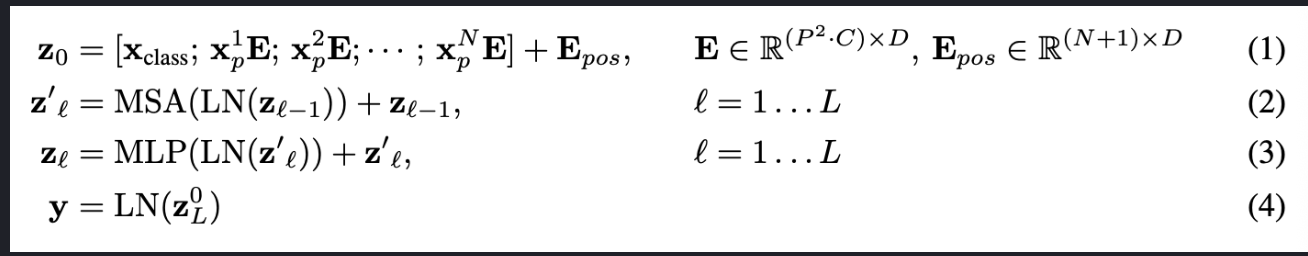

...The Transformer uses constant latent vector size $D$ through all of its layers, so we flatten the patches and map to $D$ dimensions with a trainable linear projection (Eq. 1). We refer to the output of this projection as the patch embeddings... Position embeddings are added to the patch embeddings to retain positional information. We use standard learnable 1D position embeddings...


The Transformer encoder (Vaswani et al., 2017) consists of alternating layers of multiheaded selfattention (MSA, see Appendix A) and MLP blocks (Eq. 2, 3). Layernorm (LN) is applied before every block, and residual connections after every block (Wang et al., 2019; Baevski & Auli, 2019).



Similar to BERT's [ class ] token, we prepend a learnable embedding to the sequence of embedded patches $\left(\mathbf{z}_{0}^{0}=\mathbf{x}_{\text {class }}\right)$, whose state at the output of the Transformer encoder $\left(\mathbf{z}_{L}^{0}\right)$ serves as the image representation $\mathbf{y}$ (Eq. 4)...

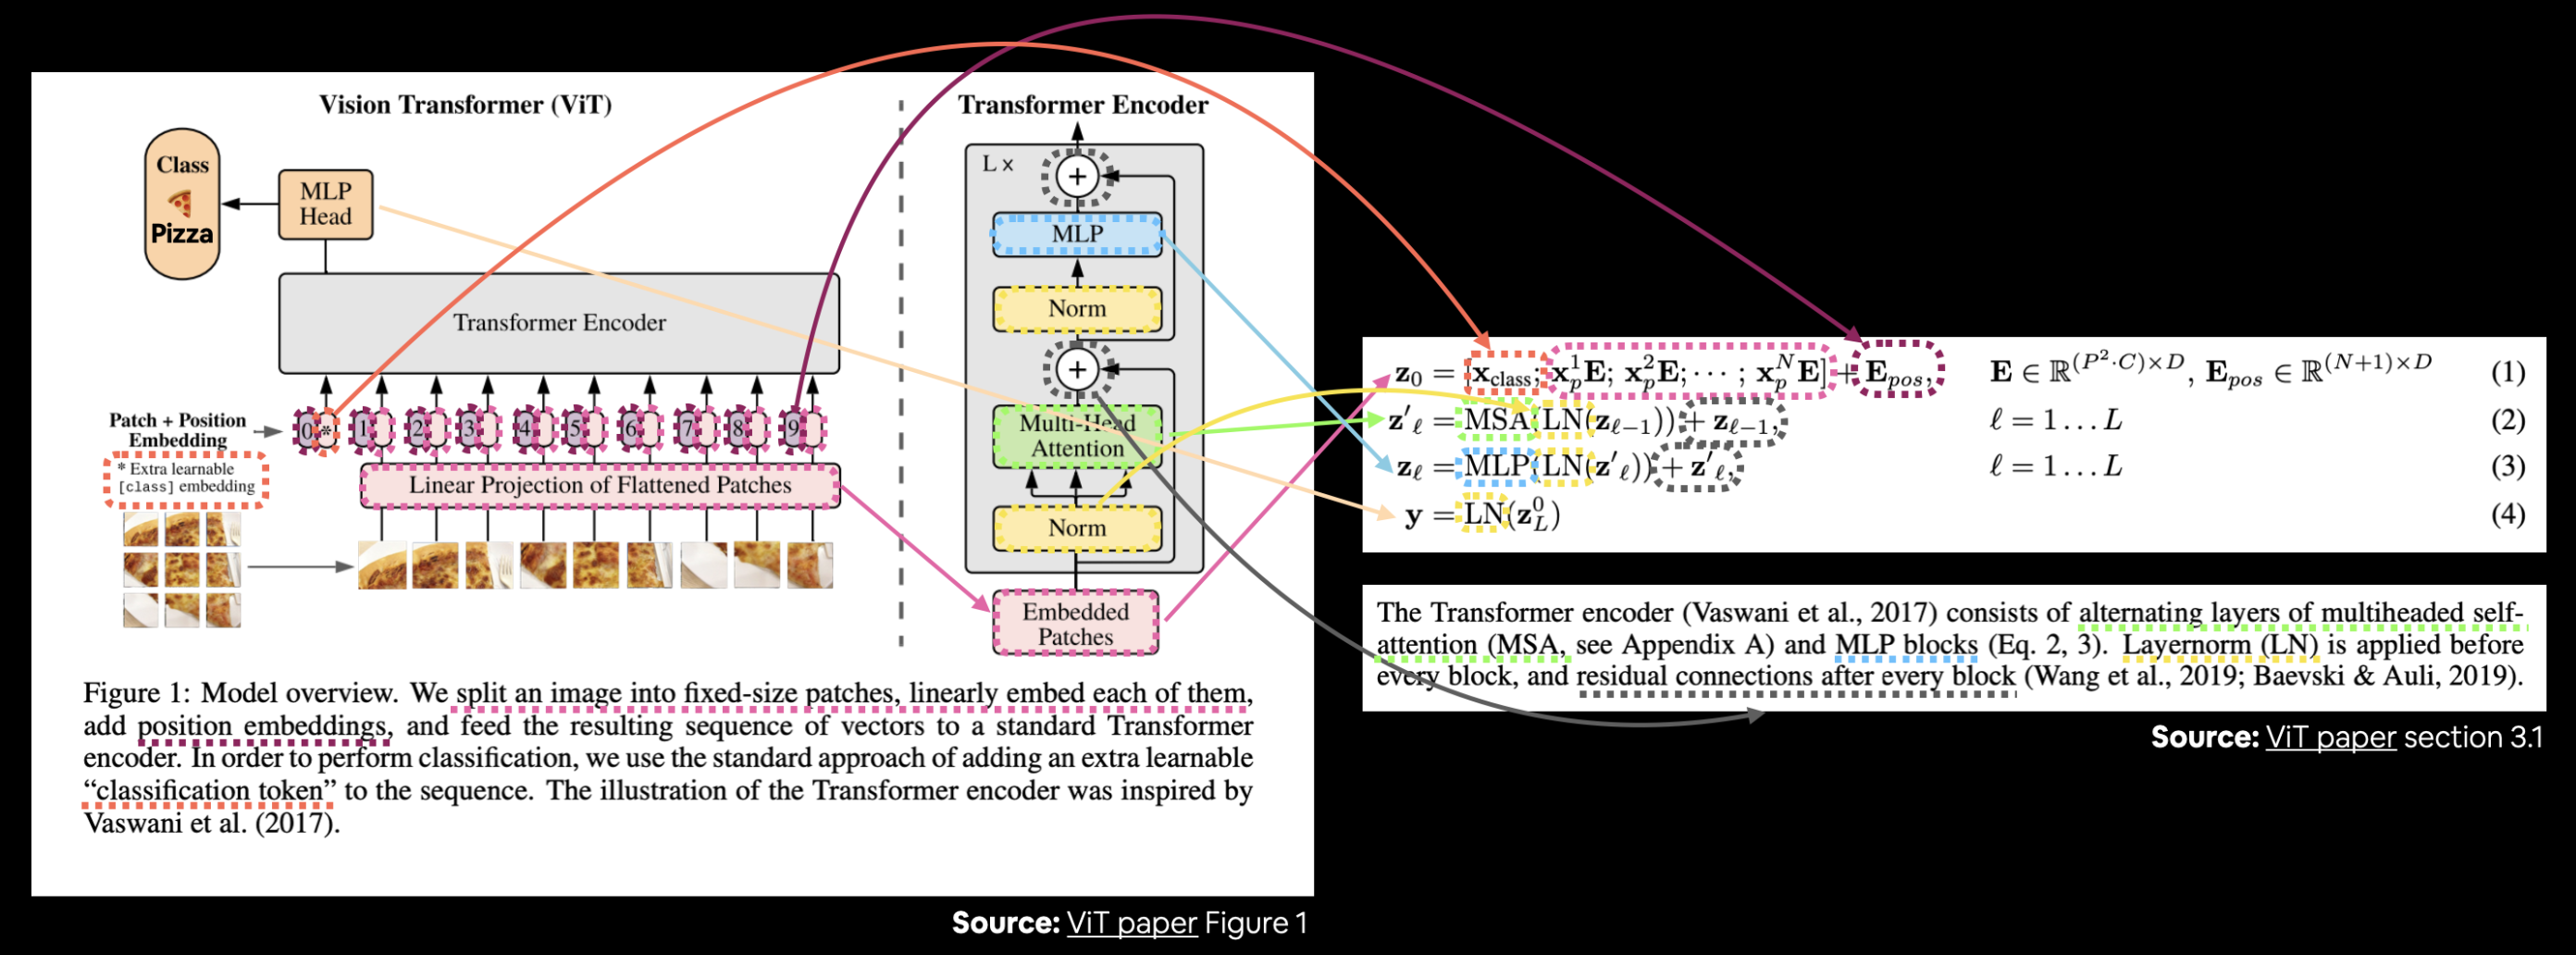

There's a lot happening in the image above but following the coloured lines and arrows reveals the main concepts of the ViT architecture.

* In all equations (except equation 4), "$\mathbf{z}$" is the raw output of a particular layer:

1. $\mathbf{z}_{0}$ is "z zero" (this is the output of the initial patch embedding layer).

2. $\mathbf{z}_{\ell}^{\prime}$ is "z of a particular layer prime" (or an intermediary value of z).

3. $\mathbf{z}_{\ell}$ is "z of a particular layer".

And $\mathbf{y}$ is the overall output of the architecture.

Similar to BERT's [ class ] token, we prepend a learnable embedding to the sequence of embedded patches $\left(\mathbf{z}_{0}^{0}=\mathbf{x}_{\text {class }}\right)$, whose state at the output of the Transformer encoder $\left(\mathbf{z}_{L}^{0}\right)$ serves as the image representation $\mathbf{y}$ (Eq. 4)...

#### 3.2.3 Equation 1 overview



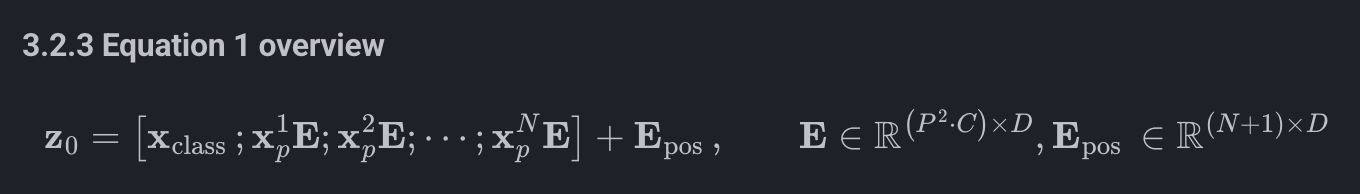

* This equation deals with the class token, patch embedding and position embedding ($\mathbf{E}$ is for embedding) of the input image.

In vector form, the embedding might look something like:


In [ ]:
# x_input =
#[class_token, image_patch_1, image_patch_2, image_patch_3..]
# + [class_token_position, image_patch_1_position,
# image_patch_2_position, image_patch_3_position...]
#

"""

Where each of the elements in the
vector is learnable (their requires_grad=True).

"""
print("3.2.3")

3.2.3


#### 3.2.4  Equation 2 overview

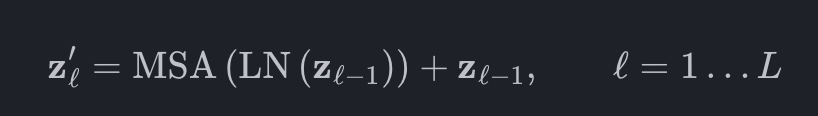

this says that for every layer from $1$ through to $L$ (the total number of layers), there's a Multi-Head Attention layer (MSA) wrapping a LayerNorm layer (LN).

The addition on the end is the equivalent of adding the input to the output and forming a skip/residual connection.

We'll call this layer the "MSA block".

In pseudocode, this might look like:

[ x_output_MSA_block = MSA_layer(LN_layer(x_input)) + x_input ]

Notice the skip connection on the end (adding the input of the layers to the output of the layers).

#### 3.2.5 Equation 3 overview


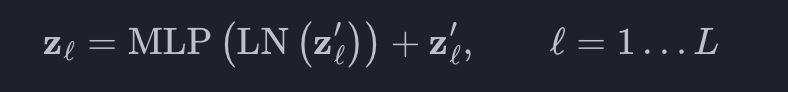

this says that for every layer from $1$ through to $L$ (the total number of layers), there's also a Multilayer Perceptron layer (MLP) wrapping a LayerNorm layer (LN).

The addition on the end is showing the presence of a skip/residual connection.

We'll call this layer the "MLP block".

In pseudocode, this might look like:

In [ ]:
"""

x_output_MLP_block = MLP_layer(LN_layer(x_output_MSA_block))
+
x_output_MSA_block

"""
# Notice the skip connection on the end (adding the input of the layers to the output of the layers).
print("")

#### 3.2.6 Equation 4 overview

Notice the skip connection on the end (adding the input of the layers to the output of the layers).

This says for the last layer $L$, the output $y$ is the 0 index token of $z$ wrapped in a LayerNorm layer (LN).

Or in our case, the 0 index of x_output_MLP_block:

In [ ]:
"""

y = Linear_layer(LN_layer(x_output_MLP_block[0]))

"""
print("")


#### 3.2.7 Exploring Table 1

This table showcasing the various hyperparameters of each of the ViT architectures.

You can see the numbers gradually increase from ViT-Base to ViT-Huge.

We're going to focus on replicating ViT-Base (start small and scale up when necessary) but we'll be writing code that could easily scale up to the larger variants

| Model | Layers | Hidden size D | MLP size | Heads | Params |
|-------|--------|---------------|----------|-------|--------|
| ViT-Base | 12 | 768 | 3072 | 12 | $86M$
| ViT-Large | 24 | 1024 | 4096 | 16 | $307M$
| ViT-Huge | 32 | 1280 | 5120 | 16 | $632M$

Breaking the hyperparameters down:

* Layers - How many Transformer Encoder blocks are there? (each of these will contain a MSA block and MLP block)

* Hidden size $D$ - This is the embedding dimension throughout the architecture, this will be the size of the vector that our image gets turned into when it gets patched and embedded. Generally, the larger the embedding dimension, the more information can be captured, the better results. However, a larger embedding comes at the cost of more computation.

* MLP size - What are the number of hidden units in the MLP layers?

* Heads - How many heads are there in the Multi-Head Attention layers?

* Params - What are the total number of parameters of the model? Generally, more parameters leads to better performance but at the cost of more computation. You'll notice even ViT-Base has far more parameters than any other model we've used so far.

### 3.3 My workflow for replicating papers
When I start working on replicating a paper, I go through the following steps:

1. Read the whole paper end-to-end once (to get an idea of the main concepts).

2. Go back through each section and see how they line up with each other and start thinking about how they might be turned into code (just like above).

3. Repeat step 2 until I've got a fairly good outline.

4. Use mathpix.com (a very handy tool) to turn any sections of the paper into markdown/LaTeX to put into notebooks.

5. Replicate the simplest version of the model possible.

6. If I get stuck, look up other examples.

# 4.  Equation 1: Split data into patches and creating the class, position and patch embedding

"it's all about the embedding."

As in, if you can represent your data in a good, learnable way (as embeddings are learnable representations), chances are, a learning algorithm will be able to perform well on them.

With that being said, let's start by creating the class, position and patch embeddings for the ViT architecture.

We'll start with the patch embedding.

This means we'll be turning our input images in a sequence of patches and then embedding those patches.

Recall that an embedding is a learnable representation of some form and is often a vector.

The term learnable is important because this means the numerical representation of an input image (that the model sees) can be improved over time.

Note :-

* Embedding matlab kisi bhi cheez (word, image patch, etc.) ko numbers ke vector mein convert karna, jisse computer usko samajh/process kar sake.

* Jaise: ek image patch (pixels) ko lo aur usko ek fixed-length number list (jaise 768 numbers) mein badal do — wahi list uski "embedding" hai, jo uska meaning/information capture karti hai.

Let's break down the text above.

* $D$ is the size of the patch embeddings, different values for $D$ for various sized ViT models can be found in Table 1.

* The image starts as 2D with size ${H \times W \times C}$.
  * $(H, W)$ is the resolution of the original image (height, width).
  * $C$ is the number of channels.

* The image gets converted to a sequence of flattened 2D patches with size ${N \times\left(P^{2} \cdot C\right)}$.

  * $(P, P)$ is the resolution of each image patch (patch size).
  * $N=H W / P^{2}$ is the resulting number of patches, which also serves as the input sequence length for the Transformer

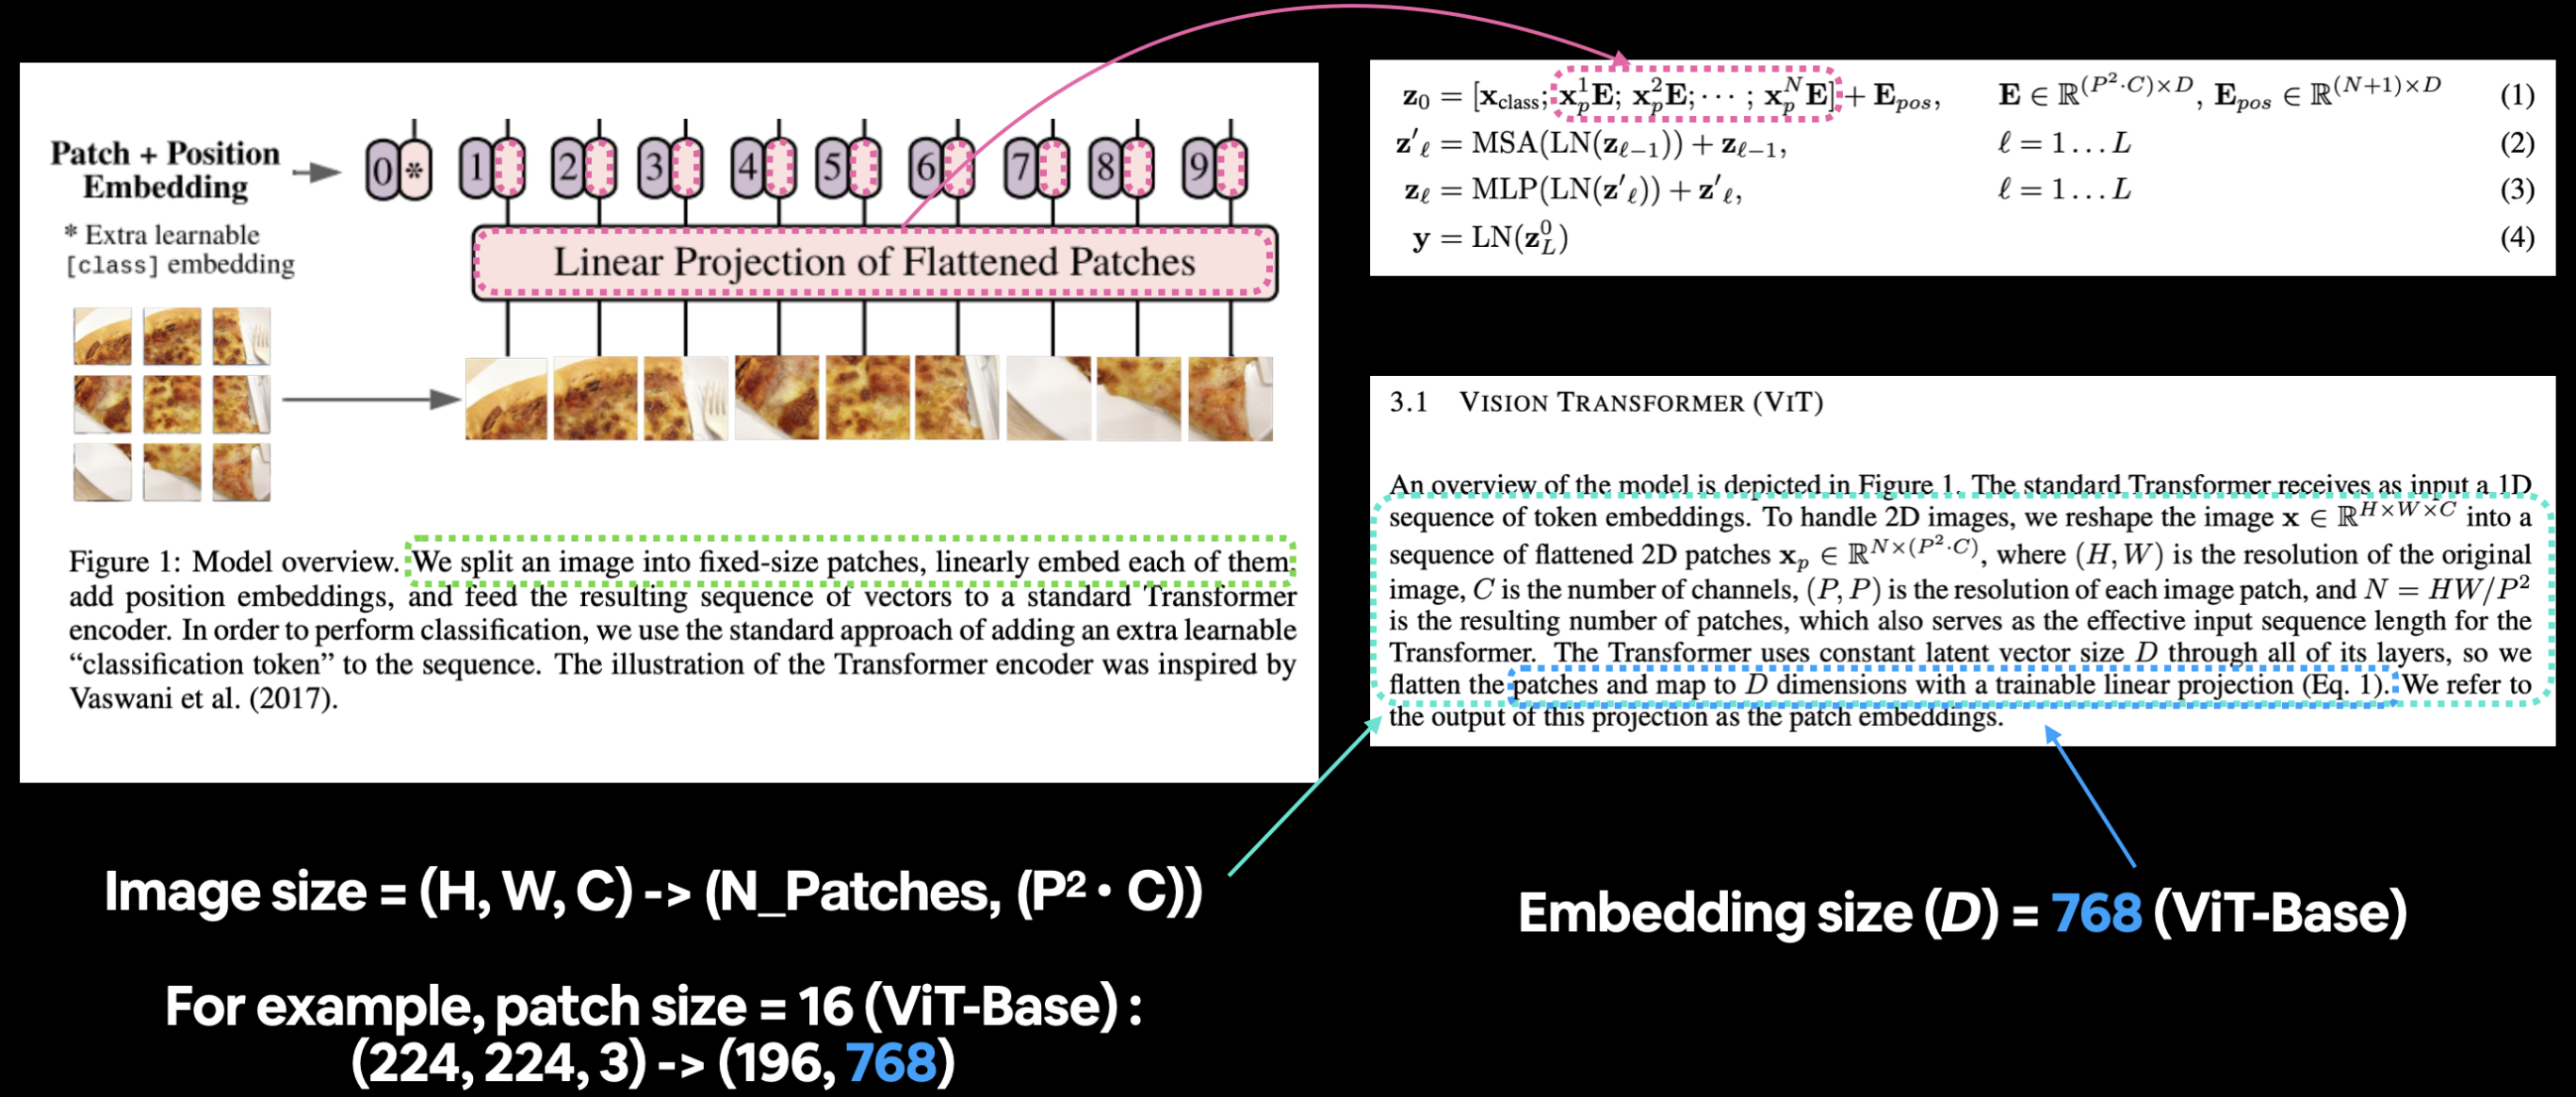

### 4.1 Calculating patch embedding input and output shapes by hand


How about we start by calculating these input and output shape values by hand?

To do so, let's create some variables to mimic each of the terms (such as $H$, $W$ etc) above.

We'll use a patch size ($P$) of 16 since it's the best performing version of ViT-Base uses (see column "ViT-B/16" of Table 5 in the ViT paper for more).

In [ ]:
# create example values
height = 224  # H ("the training resolution is 224. ")
width = 224 # W
color_channels = 3  # C
patch_size = 16  # P

# calculate N (number of patches)
number_of_patches = int((height * width ) / patch_size**2)
print(f"No. of patches (N) with image height (H = {height}) , (W = {width}) , (C = {color_channels}) , (P = {patch_size}) ")


No. of patches (N) with image height (H = 224) , (W = 224) , (C = 3) , (P = 16) 


how about we create the image output size as well?

let's replicate the input and output shapes of the patch embedding layer.

Recall:

* Input: The image starts as 2D with size ${H \times W \times C}$.
* Output: The image gets converted to a sequence of flattened 2D patches with size ${N \times\left(P^{2} \cdot C\right)}$.

In [ ]:
# input shape (this is the size of a single image )
embedding_layer_input_shape = (height , width , color_channels)

# output shape
embedding_layer_output_shape = (number_of_patches, patch_size**2 * color_channels)

print(f"input shape (single 2D image ) : {embedding_layer_input_shape}")
print(f"output shape (single 2d image flattened into patches) : {embedding_layer_output_shape}")


input shape (single 2D image ) : (224, 224, 3)
output shape (single 2d image flattened into patches) : (196, 768)


### 4.2 Tunning a single image into patches

Now we know the ideal input and output shapes for our patch embedding layer, let's move towards making it.

What we're doing is breaking down the overall architecture into smaller pieces, focusing on the inputs and outputs of individual layers.

So how do we create the patch embedding layer?

what it looks like to turn an image into patches.

Let's start with our single image

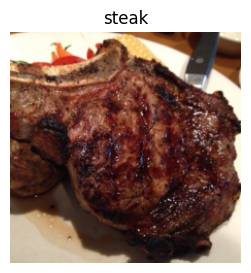

In [ ]:
# view single image
plt.figure(figsize = (4,3))
plt.imshow(image.permute(1,2,0))
plt.title(class_names[label])
plt.axis(False);


We want to turn this image into patches of itself inline with Figure 1 of the ViT paper.

How about we start by just visualizing the top row of patched pixels?

We can do this by indexing on the different image dimensions.

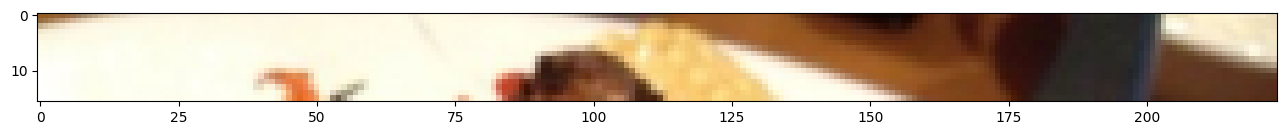

In [ ]:
# change image shape to be compatible with matplotlib (C , H , W) -> (H , W ,C)
image_permuted = image.permute(1,2,0)

# index to plot the top row of patched pixels
patch_size = 16
plt.figure(figsize = (patch_size , patch_size))
plt.imshow(image_permuted[:patch_size, : , :]);

Now we've got the top row, let's turn it into patches.

We can do this by iterating through the number of patches there'd be in the top row.

Patches kya hain?

Ek image (jaise 224x224 pixels) ko chhote-chhote squares (jaise 16x16 pixels) mein kaat diya jata hai. Har chhote square ko "patch" bolte hain. Jaise ek photo ko tukdo mein kaat diya — grid jaisa.

Fir har patch ko flatten karke ek vector (numbers ki list) banate hain — usko "patch embedding" bolte hain. Ye is liye kyunki Transformer (jo originally text ke liye bana tha) words ki jagah "tokens" leta hai — image mein patches hi "tokens" ban jaate hain.

ViT ke 4 equations (simple version):

* Equation 1 — Patch + Position Embedding: Image ko patches mein todo, unko embed karo (numbers mein convert), aur ek extra "class token" add karo (jo final classification ke liye use hoga). Position info bhi add karte hain taaki model ko pata rahe konsa patch kahan tha.

* Equation 2 — Multi-Head Self-Attention (MSA): Har patch dusre sab patches ko "dekhta" hai aur decide karta hai kaunsa patch zyada important hai (attention). Isse patches ke beech relationship samajh aata hai.

* Equation 3 — MLP block: Attention ke output ko ek chhota neural network (Linear layers) se pass karte hain, jo har patch ki representation ko refine karta hai.

* Equation 4 — Final output (Class label): Sabse end mein sirf class token liya jata hai (jo saari information collect kar chuka hota hai), aur usko ek classifier se pass karke final prediction (pizza/steak/sushi) milta hai.

Simple flow: Image → Patches → Embeddings → Attention (dekhna) → MLP (samajhna) → Class prediction

no. of patches per row : 14.0
Patch size : 16 pixels * 16 pixels 


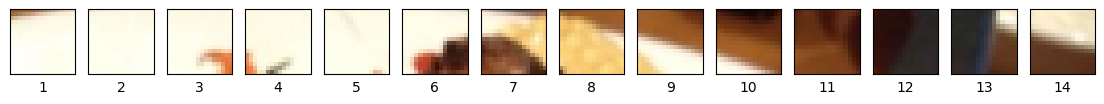

In [ ]:
# # setup hyperparameters and make sure img_size and patch_size are compatible

img_size = 224
patch_size = 16
num_patches = img_size/patch_size
assert img_size % patch_size == 0 , "Image size must be divisible by patch size"
print(f"no. of patches per row : {num_patches}\nPatch size : {patch_size} pixels * {patch_size} pixels ")

# create a series of subplots
fig, axs = plt.subplots(nrows = 1 ,
                        ncols = img_size // patch_size , # one column for each patch
                        figsize = (num_patches , num_patches),
                        sharex  = True ,
                        sharey = True)

# iterate through number of patches in the top row
for i , patch in enumerate (range(0, img_size , patch_size)):
  axs[i].imshow(image_permuted[:patch_size, patch:patch+patch_size,  :]) # keep heihgt index constant , alter the width index
  axs[i].set_xlabel(i+1) # set the label
  axs[i].set_xticks([])
  axs[i].set_yticks([])


those are some nice looking patches

How about we do it for the whole image?

This time we'll iterate through the indexes for height and width and plot each patch as it's own subplot

number of patches per row : 14.0
 Number of patches per column : 14.0
Total patches : 196.0
 Patch size : 16 pixels * 16 pixels


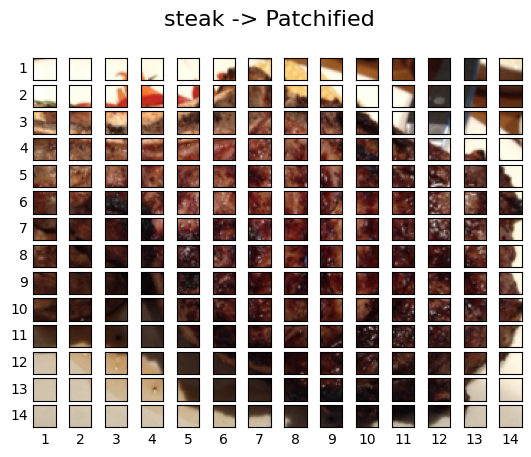

In [ ]:
#setup hyperparameters and make sure img_size and patch_size are compatible

img_size = 224
patch_size = 16
num_patches = img_size/patch_size
assert img_size % patch_size == 0 , "Image size must be divisible by patch size"
print(f"number of patches per row : {num_patches}\n "
      f"Number of patches per column : {num_patches}\n"
      f"Total patches : {num_patches*num_patches}\n "
      f"Patch size : {patch_size} pixels * {patch_size} pixels")

# create a series of subplots
fig , axs = plt.subplots(nrows = img_size // patch_size, # need int not float
                         ncols = img_size // patch_size,
                         sharex = True ,
                         sharey = True)

# loop through height and width of image
for i, patch_height in enumerate(range(0, img_size, patch_size)): # iterate through height
  for j, patch_width in enumerate(range(0, img_size, patch_size)): # iterate through width

    # plot the permuted image patch (image_permuted -> (Height, Width, color_channels ))
    axs[i, j].imshow(image_permuted[patch_height:patch_height+patch_size, # iterate through height
                                    patch_width:patch_width+patch_size, #   iterate through width
                                    :]) # get all color channels

    # set up label information , remove the ticks for clarity and set labels to outside
    axs[i,j].set_ylabel(i+1,
                        rotation = "horizontal",
                        horizontalalignment = "right" ,
                        verticalalignment = "center")
    axs[i, j].set_xlabel(j+1)
    axs[i, j].set_xticks([])
    axs[i, j].set_yticks([])
    axs[i, j].label_outer()


# set a super title
fig.suptitle(f"{class_names[label]} -> Patchified" , fontsize = 16)
plt.show()

Image patchified!

Woah, that looks cool.

Now how do we turn each of these patches into an embedding and convert them into a sequence?

Hint: we can use PyTorch layers. Can you guess which?

### 4.3 Creating image patches with torch.nn.Conv2d()

We've seen what an image looks like when it gets turned into patches, now let's start moving towards replicating the patch embedding layers with PyTorch.

To visualize our single image we wrote code to loop through the different height and width dimensions of a single image and plot individual patches.

This operation is very similar to the convolutional operation we saw in 03. PyTorch Computer Vision section 7.1: Stepping through nn.Conv2d().

In fact, the authors of the ViT paper mention in section 3.1 that the patch embedding is achievable with a convolutional neural network (CNN):

* Hybrid Architecture. As an alternative to raw image patches, the input sequence can be formed from feature maps of a CNN (LeCun et al., 1989). In this hybrid model, the patch embedding projection $\mathbf{E}$ (Eq. 1) is applied to patches extracted from a CNN feature map. As a special case, the patches can have spatial size $1 \times 1$, which means that the input sequence is obtained by simply flattening the spatial dimensions of the feature map and projecting to the Transformer dimension. The classification input embedding and position embeddings are added as described above.

By setting the kernel_size and stride parameters of a torch.nn.Conv2d() layer equal to the patch_size, we can effectively get a layer that splits our image into patches and creates a learnable embedding (referred to as a "Linear Projection" in the ViT paper) of each patch.

Remember our ideal input and output shapes for the patch embedding layer?

Input: The image starts as 2D with size ${H \times W \times C}$.
Output: The image gets converted to a 1D sequence of flattened 2D patches with size ${N \times\left(P^{2} \cdot C\right)}$.
* Or for an image size of 224 and patch size of 16:
  * Input (2D image): (224, 224, 3) -> (height, width, color channels)
  * Output (flattened 2D patches): (196, 768) -> (number of patches, embedding dimension)

We can recreate these with:

  * torch.nn.Conv2d() for turning our image into patches of CNN feature maps.
  * torch.nn.Flatten() for flattening the spatial dimensions of the feature map.

Let's start with the torch.nn.Conv2d() layer.

We can replicate the creation of patches by setting the kernel_size and stride equal to patch_size.

This means each convolutional kernel will be of size (patch_size x patch_size) or if patch_size=16, (16 x 16) (the equivalent of one whole patch).

And each step or stride of the convolutional kernel will be patch_size pixels long or 16 pixels long (equivalent of stepping to the next patch).

We'll set in_channels=3 for the number of color channels in our image and we'll set out_channels=768, the same as the $D$ value in Table 1 for ViT-Base (this is the embedding dimension, each image will be embedded into a learnable vector of size 768).

In [ ]:
from torch import nn

# set the patch size
patch_size = 16

# create the conv2d layer with hyperparameters from the Vit paper
conv2d = nn.Conv2d(in_channels = 3 , # number of color_channels
                   out_channels = 768 , # from table 1 : hidden size D, this is embedding size
                   kernel_size = patch_size, # could also use (patch_size , patch_size)
                   stride = patch_size ,
                   padding = 0)


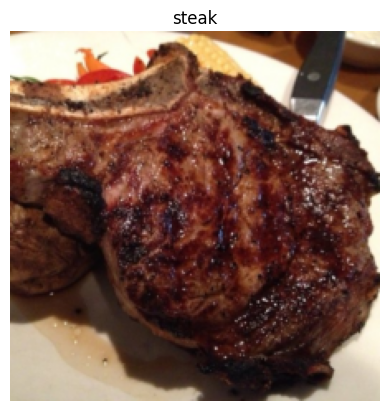

In [ ]:
# now we've got a convolutional layer , let's see what happens when we pass a single image through it .
plt.imshow(image.permute(1,2,0)) # adjust for matplotlib
plt.title(class_names[label])
plt.axis(False);

In [ ]:
# pass the image   through the convolutional layer
image_out_of_conv = conv2d(image.unsqueeze(0)) # add a single batch dimension (H, W , C) -> (batch, H, W , Color_channels)
print(image_out_of_conv.shape)

torch.Size([1, 768, 14, 14])


Passing our image through the convolutional layer turns it into a series of 768 (this is the embedding size or $D$) feature/activation maps.

So its output shape can be read as:

*  torch.Size([1, 768, 14, 14]) -> [batch_size, embedding_dim, feature_map_height, feature_map_width]

Let's visualize five random feature maps and see what they look like.

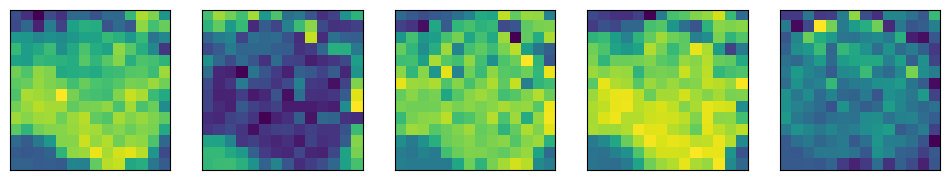

In [ ]:
# plot random 5 convolutional feature maps
import random
random_indexes = random.sample(range(0, 768) , k = 5) # pick 5 numbers between 0 and the embedding size

# create plot
fig , axs = plt.subplots (nrows = 1 , ncols =5 , figsize=(12,12))

# plot random image features maps
for i , idx in enumerate(random_indexes):
  image_conv_feature_map = image_out_of_conv[:, idx, : , :] #index on the output tensor of the convolutional  layer
  axs[i].imshow(image_conv_feature_map.squeeze().detach().numpy() )
  axs[i].set(xticklabels = [], yticklabels = [] , xticks = [], yticks = []);


* Colors different kyun: Ye feature maps hain, real image nahi — har channel model ne khud seekha hai (edges, textures, patterns detect karne ke liye), so unka color matplotlib ka default colormap (viridis) use karta hai jo random-looking values ko blue-green-yellow mein map karta hai. Actual image colors se koi relation nahi hai.

Notice how the feature maps all kind of represent the original image, after visualizing a few more you can start to see the different major outlines and some major features.

The important thing to note is that these features may change over time as the neural network learns.

And because of these, these feature maps can be considered a learnable embedding of our image.

Let's check one out in numerical form.

In [ ]:
# get a single feature map in tensor form

single_feature_map = image_out_of_conv[: ,0, :, :]
single_feature_map, single_feature_map.requires_grad


(tensor([[[ 0.4404,  0.3952,  0.4698,  0.3072,  0.4066,  0.4298,  0.0150,
            0.3709,  0.3657,  0.2318,  0.2077,  0.0514, -0.0300,  0.1200],
          [ 0.3185,  0.4282,  0.4353,  0.0783,  0.3656,  0.2462,  0.3025,
            0.1492,  0.0861,  0.3104,  0.7387,  0.1702,  0.1103,  0.0956],
          [ 0.2416,  0.1868,  0.2249,  0.2598,  0.1555,  0.1651,  0.2055,
            0.1379,  0.2019, -0.0992,  0.3498,  0.1644,  0.5024,  0.1371],
          [ 0.2652,  0.2323,  0.1935,  0.1753,  0.3516,  0.1207,  0.1207,
            0.1397,  0.2659,  0.0470,  0.0362, -0.0194,  0.1973,  0.4888],
          [ 0.2064,  0.1021,  0.2390,  0.1147,  0.0720,  0.1835,  0.0215,
            0.1080,  0.1392,  0.1462,  0.1969,  0.1135,  0.1236,  0.0430],
          [ 0.0517,  0.1533,  0.0651,  0.0918,  0.2027,  0.2401,  0.1406,
            0.2213,  0.0619,  0.0924,  0.1213,  0.1315,  0.2223, -0.1010],
          [ 0.1265,  0.0746,  0.0715, -0.0486,  0.2030,  0.1592,  0.1585,
            0.1430,  0.0104,  0.

The grad_fn output of the single_feature_map and the requires_grad=True attribute means PyTorch is tracking the gradients of this feature map and it will be updated by gradient descent during training.

### 4.4 Flattening the patch embedding with torch.nn.Flatten()

we've turned our image into patch embeddings but they're still in 2D format.

how do we get them into the desired output shape of the patch embedding layer of the ViT

* Desired output (1D sequence of flattened 2D patches): (196, 768) -> (number of patches, embedding dimension) -> ${N \times\left(P^{2} \cdot C\right)}$

Let's check the current shape.

In [ ]:
# current tensor shape
print(f"current tensor shape : {image_out_of_conv.shape}")

current tensor shape : torch.Size([1, 768, 14, 14])


Well we've got the 768 part ( $(P^{2} \cdot C)$ ) but we still need the number of patches ($N$).

Reading back through section 3.1 of the ViT paper it says (bold mine):

* As a special case, the patches can have spatial size $1 \times 1$, which means that the input sequence is obtained by simply flattening the spatial dimensions of the feature map and projecting to the Transformer dimension.

But we don't want to flatten the whole tensor, we only want to flatten the "spatial dimensions of the feature map".

Which in our case is the feature_map_height and feature_map_width dimensions of image_out_of_conv.

So how about we create a torch.nn.Flatten() layer to only flatten those dimensions, we can use the start_dim and end_dim parameters to set that up?

In [ ]:
# create flatten layer
flatten = nn.Flatten(start_dim = 2 , # flatten feature_map_height (dimension 2)
                     end_dim = 3) # flatten feature_map_width (dimension 3)


Nice! Now let's put it all together!

We'll:

1. Take a single image.
2. Put in through the convolutional layer (conv2d) to turn the image into 2D feature maps (patch embeddings).
3. Flatten the 2D feature map into a single sequence.

Image feature map shape : torch.Size([1, 768, 14, 14])
Flattened image feature map shape : torch.Size([1, 768, 196])


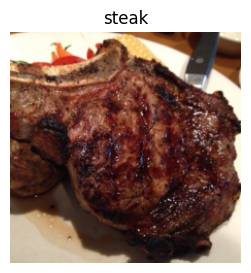

In [ ]:
# 1. view single image
plt.figure(figsize = (4,3))
plt.imshow(image.permute(1,2,0))
plt.title(class_names[label])
plt.axis(False)

# 2. Turn image into feature maps
image_out_of_conv = conv2d(image.unsqueeze(0)) # add batch dimension to avoid shape errors
print(f"Image feature map shape : {image_out_of_conv.shape}")

# flatten the feature maps
image_out_of_conv_flattened = flatten(image_out_of_conv)
print(f"Flattened image feature map shape : {image_out_of_conv_flattened.shape}")


our image_out_of_conv_flattened shape is very close to our desired output shape:

* Desired output (flattened 2D patches): (196, 768) -> ${N \times\left(P^{2} \cdot C\right)}$

* Current shape: (1, 768, 196)


The only difference is our current shape has a batch size and the dimensions are in a different order to the desired output and to fix  we rearrange the dimensions?:
1. We can do so with torch.Tensor.permute() just like we do when rearranging image tensors to plot them with matplotlib.



In [ ]:
# get flattened image patch embeddings in right shape
image_out_of_conv_flattened_reshaped = image_out_of_conv_flattened.permute(0,2,1) # [batch_size, P^2•C, N] -> [batch_size, N, P^2•C]
print(f"patch embedding sequence shape : {image_out_of_conv_flattened_reshaped.shape} -> [batch_size , num_patches , embedding_size] ")



patch embedding sequence shape : torch.Size([1, 196, 768]) -> [batch_size , num_patches , embedding_size] 


We've now matched the desired input and output shapes for the patch embedding layer of the ViT architecture using a couple of PyTorch layers.

How about we visualize one of the flattened feature maps?

(np.float64(-0.5), np.float64(195.5), np.float64(0.5), np.float64(-0.5))

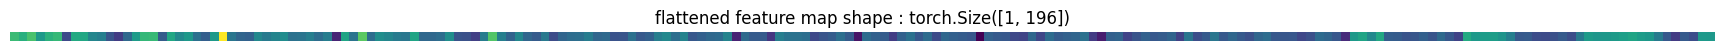

In [ ]:
# get a single flattened feature map
single_flattened_feature_map = image_out_of_conv_flattened_reshaped[:, :, 0] # index : (batch_size , number_of_batches, embedding_dimension)

# plot the flattened feature map visually
plt.figure(figsize = (22, 22))
plt.imshow(single_flattened_feature_map.detach().numpy())
plt.title(f"flattened feature map shape : {single_flattened_feature_map.shape}")
plt.axis(False)

Note: The original Transformer architecture was designed to work with text. The Vision Transformer architecture (ViT) had the goal of using the original Transformer for images. This is why the input to the ViT architecture is processed in the way it is. We're essentially taking a 2D image and formatting it so it appears as a 1D sequence of text.



In [ ]:
# see the flattened feature map as a tensor
single_flattened_feature_map , single_flattened_feature_map.requires_grad , single_flattened_feature_map.shape


(tensor([[ 0.4404,  0.3952,  0.4698,  0.3072,  0.4066,  0.4298,  0.0150,  0.3709,
           0.3657,  0.2318,  0.2077,  0.0514, -0.0300,  0.1200,  0.3185,  0.4282,
           0.4353,  0.0783,  0.3656,  0.2462,  0.3025,  0.1492,  0.0861,  0.3104,
           0.7387,  0.1702,  0.1103,  0.0956,  0.2416,  0.1868,  0.2249,  0.2598,
           0.1555,  0.1651,  0.2055,  0.1379,  0.2019, -0.0992,  0.3498,  0.1644,
           0.5024,  0.1371,  0.2652,  0.2323,  0.1935,  0.1753,  0.3516,  0.1207,
           0.1207,  0.1397,  0.2659,  0.0470,  0.0362, -0.0194,  0.1973,  0.4888,
           0.2064,  0.1021,  0.2390,  0.1147,  0.0720,  0.1835,  0.0215,  0.1080,
           0.1392,  0.1462,  0.1969,  0.1135,  0.1236,  0.0430,  0.0517,  0.1533,
           0.0651,  0.0918,  0.2027,  0.2401,  0.1406,  0.2213,  0.0619,  0.0924,
           0.1213,  0.1315,  0.2223, -0.1010,  0.1265,  0.0746,  0.0715, -0.0486,
           0.2030,  0.1592,  0.1585,  0.1430,  0.0104,  0.0522,  0.0776,  0.1449,
           0.075

We've turned our single 2D image into a 1D learnable embedding vector (or "Linear Projection of Flattened Patches" in Figure 1 of the ViT paper).

### 4.5 Turning the ViT patch embedding layer into a PyTorch module

Time to put everything we've done for creating the patch embedding into a single PyTorch layer.

We can do so by subclassing nn.Module and creating a small PyTorch "model" to do all of the steps above.

Specifically we'll:

1. Create a class called PatchEmbedding which subclasses nn.Module (so it can be used a PyTorch layer).

2. Initialize the class with the parameters in_channels=3, patch_size=16 (for ViT-Base) and embedding_dim=768 (this is $D$ for ViT-Base from Table 1).

3. Create a layer to turn an image into patches using nn.Conv2d() (just like in 4.3 above).

4. Create a layer to flatten the patch feature maps into a single dimension (just like in 4.4 above).

5. Define a forward() method to take an input and pass it through the layers created in 3 and 4.

6. Make sure the output shape reflects the required output shape of the ViT architecture (${N \times\left(P^{2} \cdot C\right)}$).

In [ ]:
# 1. create a class with subclasses nn.Module
class PatchEmbedding(nn.Module):
  """Turns a 2D input image into a 1D sequence learnable embedding vector.

    Args:
        in_channels (int): Number of color channels for the input images. Defaults to 3.
        patch_size (int): Size of patches to convert input image into. Defaults to 16.
        embedding_dim (int): Size of embedding to turn image into. Defaults to 768.
    """

  # 2. Initialize the class with appropiate variables
  def __init__(self,
               in_channels : int =3 ,
               patch_size : int = 16,
               embedding_dim : int = 768):
    super().__init__()

    # 3. create a layer to turn an image into patches
    self.patcher = nn.Conv2d(in_channels = in_channels,
                             out_channels = embedding_dim ,
                             kernel_size = patch_size,
                             stride = patch_size ,
                             padding = 0)

    # 4. create a layer to flatten the patch feature maps into a single dimension
    self.flatten = nn.Flatten(start_dim = 2, # only flatten the feature map dimensions into a single vector
                              end_dim = 3 )


  # 5. define the forward method
  def forward(self, x):
    # create assertion to check that inputs are the correct shape
    image_resolution = x.shape[-1]
    assert image_resolution % patch_size == 0 , f"Input image size must be divisible by patch size , image shape : {image_resolution} , patch size : {patch_size}"

    # perform the forward pass
    x_patched = self.patcher(x)
    x_flattened = self.flatten(x_patched)

    # 6. make sure the output shape ahs the right order
    return x_flattened.permute(0,2,1) # adjust so the embedding is on the final dimension [batch_size, P^2•C, N] -> [batch_size, N, P^2•C]


PatchEmbedding layer created!

Let's try it out on a single image.

In [ ]:
set_seeds()

# create an instance of patch embedding layer
patchify = PatchEmbedding(in_channels = 3 ,
                          patch_size = 16,
                          embedding_dim = 768)

# pass a single image through
print(f"Input image shape : {image.unsqueeze(0).shape}")
patch_embedded_image = patchify(image.unsqueeze(0)) # add an extra batch dimension on the 0th index, otherwise will error
print(f"output patch embedding shape : {patch_embedded_image.shape}")


Input image shape : torch.Size([1, 3, 224, 224])
output patch embedding shape : torch.Size([1, 196, 768])


Short summary :-
1. The output shape matches the ideal input and output shapes we'd like to see from the patch embedding layer:

2. Input: The image starts as 2D with size ${H \times W \times C}$.
Output: The image gets converted to a 1D sequence of flattened 2D patches with size ${N \times\left(P^{2} \cdot C\right)}$.

Where:

* $(H, W)$ is the resolution of the original image.
* $C$ is the number of channels.
* $(P, P)$ is the resolution of each image patch (patch size).
* $N=H W / P^{2}$ is the resulting number of patches, which also serves as the effective input sequence length for the Transformer.

Note:- what's done and What to do next

* Our PatchEmbedding class (right) replicates the patch embedding of the ViT architecture from Figure 1 and Equation 1 from the ViT paper (left). However, the learnable class embedding and position embeddings haven't been created yet.

In [ ]:
# Let's now get a summary of our PatchEmbedding layer.

# create random input sizes
random_input_image = (1, 3, 224, 224)
random_input_image_error = (1, 3, 250 , 250)# will error because image size is incompatible with patch_size

# # Get a summary of the input and outputs of PatchEmbedding (uncomment for full output)
summary(PatchEmbedding(),
        input_size = random_input_image, # # try swapping this for "random_input_image_error"
        col_names = ["input_size" , "output_size" , "num_params" , "trainable"],
        col_width = 20,
        row_settings = ["var_names"])


Layer (type (var_name))                  Input Shape          Output Shape         Param #              Trainable
PatchEmbedding (PatchEmbedding)          [1, 3, 224, 224]     [1, 196, 768]        --                   True
├─Conv2d (patcher)                       [1, 3, 224, 224]     [1, 768, 14, 14]     590,592              True
├─Flatten (flatten)                      [1, 768, 14, 14]     [1, 768, 196]        --                   --
Total params: 590,592
Trainable params: 590,592
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 115.76
Input size (MB): 0.60
Forward/backward pass size (MB): 1.20
Params size (MB): 2.36
Estimated Total Size (MB): 4.17

### 4.6 Creating the class token embedding
Okay we've made the image patch embedding, time to get to work on the class token embedding.

Or $\mathbf{x}_\text {class }$ from equation 1

Note: BERT (Bidirectional Encoder Representations from Transformers) is one of the original machine learning research papers to use the Transformer architecture to achieve outstanding results on natural language processing (NLP) tasks and is where the idea of having a [ class ] token at the start of a sequence originated, class being a description for the "classification" class the sequence belonged to.

So we need to "preprend a learnable embedding to the sequence of embedded patches".

Let's start by viewing our sequence of embedded patches tensor (created in section 4.5) and its shape.

In [ ]:
# view the patch embedding and patch embedding shape
print(patch_embedded_image)
print(patch_embedded_image.shape)

tensor([[[-1.1494,  0.3451, -0.3087,  ...,  0.7067, -0.3610,  0.2934],
         [-1.0255,  0.2790, -0.2944,  ...,  0.7646, -0.4480,  0.3539],
         [-1.0037,  0.2025, -0.2606,  ...,  0.7224, -0.5311,  0.3866],
         ...,
         [-0.2715,  0.1007, -0.3576,  ...,  0.4479, -0.0638,  0.1143],
         [-0.9809,  0.2977, -0.3050,  ...,  0.6313, -0.2039,  0.3035],
         [-0.8394,  0.2236, -0.2043,  ...,  0.6067, -0.3898,  0.2948]]],
       grad_fn=<PermuteBackward0>)
torch.Size([1, 196, 768])


To "prepend a learnable embedding to the sequence of embedded patches" we need to create a learnable embedding in the shape of the embedding_dimension ($D$) and then add it to the number_of_patches dimension.

Or in pseudocode:

patch_embedding = [image_patch_1, image_patch_2, image_patch_3...]
class_token = learnable_embedding
patch_embedding_with_class_token = torch.cat((class_token, patch_embedding), dim=1)
Notice the concatenation (torch.cat()) happens on dim=1 (the number_of_patches dimension).

Let's create a learnable embedding for the class token.

To do so, we'll get the batch size and embedding dimension shape and then we'll create a torch.ones() tensor in the shape [batch_size, 1, embedding_dimension].

And we'll make the tensor learnable by passing it to nn.Parameter() with requires_grad=True.

In [ ]:
# get the batch size and embedding dimension
batch_size = patch_embedded_image.shape[0]
print(batch_size)
embedding_dimension = patch_embedded_image.shape[-1]
embedding_dimension

1


768

Simple samjho: Ab tak humare paas 196 patches hain, har ek apna embedding (768 numbers) rakhta hai. Lekin final classification (pizza/steak/sushi) ke liye humein ek single summary chahiye jo poori image ko represent kare.

Class token kya hai: Ek extra "dummy patch" jo shuruwat mein add karte hain — iska koi real image data nahi hota, ye khaali/learnable numbers hote hain. Training ke dauran, ye token saare 196 patches se information collect karna seekh leta hai (attention mechanism ke through). End mein, sirf isi class token ko use karke final prediction nikalte hain.

Real life analogy: Socho class mein 196 students hain, aur ek "class representative" hai jo shuru mein khaali hota hai (kuch nahi jaanta), lekin training ke dauran wo har student se interact karta hai aur seekhta hai. Final exam mein sirf representative se poocha jata hai "class ka overall result kya hai" — wahi hoga class token ka role.

In [ ]:
# create the class token embedding as a learnable parameter that shares the same size as the mebedding dimension (D)
class_token = nn.Parameter(torch.ones(batch_size , 1, embedding_dimension), # [batch_size , no_of_tokens , embedding_dimension]
                           requires_grad = True) # make sure the embedding is learnable

# show the first 10 examples of the class_token
print(class_token[:, :, :10])

# print the class_token shape
print(f"class token shape : {class_token.shape} -> [batch_size , no_of_tokens , embedding_dimension]")



tensor([[[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]]], grad_fn=<SliceBackward0>)
class token shape : torch.Size([1, 1, 768]) -> [batch_size , no_of_tokens , embedding_dimension]


Note: Here we're only creating the class token embedding as torch.ones() for demonstration purposes, in reality, you'd likely create the class token embedding with torch.randn() (since machine learning is all about harnessing the power of controlled randomness, you generally start with a random number and improve it over time)

we've got the class token embedding ,let's prepend it to our sequence of image patches, patch_embedded_image.

We can do so using torch.cat() and set dim=1 (so class_token's number_of_tokens dimension is prepended to patch_embedded_image's number_of_patches dimension).

In [ ]:
# add the class token embedding to the front of the patch embedding
patch_embedded_image_with_class_embedding = torch.cat((class_token, patch_embedded_image),
                                                      dim = 1) # concat on first dimension

# print the sequence of patch embeddings with the prepended class token embedding
print(patch_embedded_image_with_class_embedding)
print(f"sequence of patch embeddings with class token prepended shape : {patch_embedded_image_with_class_embedding}")


tensor([[[ 1.0000,  1.0000,  1.0000,  ...,  1.0000,  1.0000,  1.0000],
         [-1.1494,  0.3451, -0.3087,  ...,  0.7067, -0.3610,  0.2934],
         [-1.0255,  0.2790, -0.2944,  ...,  0.7646, -0.4480,  0.3539],
         ...,
         [-0.2715,  0.1007, -0.3576,  ...,  0.4479, -0.0638,  0.1143],
         [-0.9809,  0.2977, -0.3050,  ...,  0.6313, -0.2039,  0.3035],
         [-0.8394,  0.2236, -0.2043,  ...,  0.6067, -0.3898,  0.2948]]],
       grad_fn=<CatBackward0>)
sequence of patch embeddings with class token prepended shape : tensor([[[ 1.0000,  1.0000,  1.0000,  ...,  1.0000,  1.0000,  1.0000],
         [-1.1494,  0.3451, -0.3087,  ...,  0.7067, -0.3610,  0.2934],
         [-1.0255,  0.2790, -0.2944,  ...,  0.7646, -0.4480,  0.3539],
         ...,
         [-0.2715,  0.1007, -0.3576,  ...,  0.4479, -0.0638,  0.1143],
         [-0.9809,  0.2977, -0.3050,  ...,  0.6313, -0.2039,  0.3035],
         [-0.8394,  0.2236, -0.2043,  ...,  0.6067, -0.3898,  0.2948]]],
       grad_fn=<CatBa

### 4.7 Creating the position embedding

$\mathbf{E}_{\text {pos }}$ from equation 1 where $E$ stands for "embedding".

1. Position embeddings are added to the patch embeddings to retain positional information. We use standard learnable 1D position embeddings, since we have not observed significant performance gains from using more advanced 2D-aware position embeddings (Appendix D.4). The resulting sequence of embedding vectors serves as input to the encoder.

  * Position embedding matlab: har patch ko uska position/location yaad dilana — kyunki jab hum patches ko flatten karke sequence banate hain, model ko pata nahi chalta ki koi patch image mein kahan tha (top-left, center, bottom-right, etc.) — order ki information kho jaati hai.

  * Simple example: Socho ek jigsaw puzzle ke 196 tukde alag-alag kar diye, aur unko ek line mein rakh diya. Ab agar sirf tukde dekho, pata nahi chalega konsa tukda kahan fit hota tha. Position embedding is problem ko solve karta hai — har patch ke saath uska "address/number" bhi jod dete hain, taaki model samajh sake konsa patch kahan tha.


* Training ke dauran, model ye position embeddings khud seekh leta hai — taaki wo samajh sake spatial relationships (jaise "ye patch upar wala hai," "ye patch beech mein hai").

Note :- Kaise kaam karta hai: Ek learnable vector (jaise class token) banate hain, jiska shape hota hai [number_of_patches+1, embedding_dim] (197, 768) — har position ke liye ek unique embedding. Isko simply patch embeddings mein add kar dete hain (concatenate nahi, addition):

* patch_embedding_with_position = patch_embedding_with_class_token + position_embedding

In [ ]:
# view the sequence of patch embeddings with the prepended class embedding
patch_embedded_image_with_class_embedding, patch_embedded_image_with_class_embedding.shape

(tensor([[[ 1.0000,  1.0000,  1.0000,  ...,  1.0000,  1.0000,  1.0000],
          [-1.1494,  0.3451, -0.3087,  ...,  0.7067, -0.3610,  0.2934],
          [-1.0255,  0.2790, -0.2944,  ...,  0.7646, -0.4480,  0.3539],
          ...,
          [-0.2715,  0.1007, -0.3576,  ...,  0.4479, -0.0638,  0.1143],
          [-0.9809,  0.2977, -0.3050,  ...,  0.6313, -0.2039,  0.3035],
          [-0.8394,  0.2236, -0.2043,  ...,  0.6067, -0.3898,  0.2948]]],
        grad_fn=<CatBackward0>),
 torch.Size([1, 197, 768]))

Equation 1 states that the position embeddings ($\mathbf{E}_{\text {pos }}$) should have the shape $(N + 1) \times D$ :

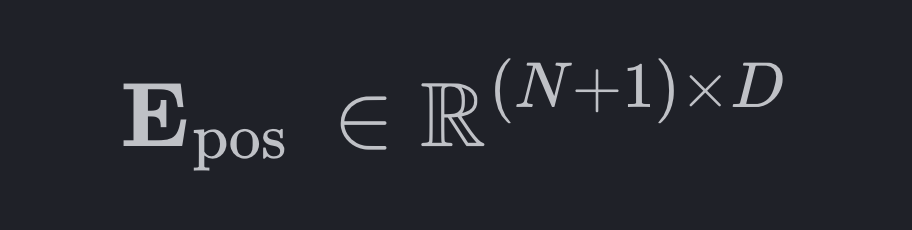

Where:

* $N=H W / P^{2}$ is the resulting number of patches, which also serves as the effective input sequence length for the Transformer (number of patches).

* $D$ is the size of the patch embeddings, different values for $D$ can be found in Table 1 (embedding dimension).

1. we've got both of these values already.

2. So let's make a learnable 1D embedding with torch.ones() to create $\mathbf{E}_{\text {pos }}$

In [ ]:
# calculate N (no.of patches)
number_of_patches = int((height * width) / (patch_size**2))
print(f"number_of_patches :{number_of_patches} ")

# get embedding dimension
embedding_dimension = patch_embedded_image_with_class_embedding.shape[2]

# Create the learnable 1D position embedding
position_embedding = nn.Parameter(torch.ones(1,
                                             number_of_patches+1,
                                             embedding_dimension),
                                  requires_grad = True) # make sure it's learnable

# show the first 10 sequences and 10 position embedding values and check the shape of the position embedding
print(position_embedding[:, :10 :10])
print(f"Position embedding shape : {position_embedding.shape} -> [batch_size , number_of_patches , embedding_dimension ]")


number_of_patches :196 
tensor([[[1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
          1., 1., 1., 1., 1., 1., 1., 1.

Note: Only creating the position embedding as torch.ones() for demonstration purposes, in reality, you'd likely create the position embedding with torch.randn() (start with a random number and improve via gradient descent).

In [ ]:
# add the position embedding to the patch and class token embedding
patch_and_position_embedding = patch_embedded_image_with_class_embedding + position_embedding
print(patch_and_position_embedding)

print(f"patch embeddings ,class token prepended and positional embeddings added shape : {patch_and_position_embedding.shape} -> [batch_size , number_of_patches , embedding_dimension ]")


tensor([[[ 2.0000,  2.0000,  2.0000,  ...,  2.0000,  2.0000,  2.0000],
         [-0.1494,  1.3451,  0.6913,  ...,  1.7067,  0.6390,  1.2934],
         [-0.0255,  1.2790,  0.7056,  ...,  1.7646,  0.5520,  1.3539],
         ...,
         [ 0.7285,  1.1007,  0.6424,  ...,  1.4479,  0.9362,  1.1143],
         [ 0.0191,  1.2977,  0.6950,  ...,  1.6313,  0.7961,  1.3035],
         [ 0.1606,  1.2236,  0.7957,  ...,  1.6067,  0.6102,  1.2948]]],
       grad_fn=<AddBackward0>)
patch embeddings ,class token prepended and positional embeddings added shape : torch.Size([1, 197, 768]) -> [batch_size , number_of_patches , embedding_dimension ]


Note: We could put both the class token embedding and position embedding into their own layer if we wanted to. But we'll see later on in section 8 how they can be incorporated into the overall ViT architecture's forward() method.

The workflow we've used for adding the position embeddings to the sequence of patch embeddings and class token.

* Note: torch.ones() only used to create embeddings for illustration purposes, in practice, you'd likely use torch.randn() to start with a random number.

### 4.8 Putting it all together: from image to embedding

Alright, we've come a long way in terms of turning our input images into an embedding and replicating equation 1 from section 3.1 of the ViT paper:

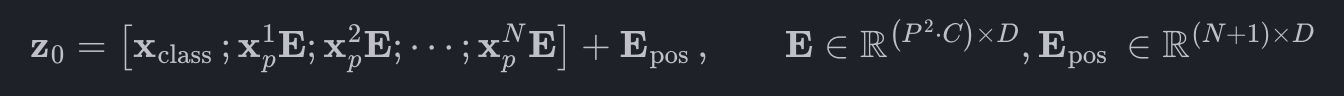

Let's now put everything together in a single code cell and go from input image ($\mathbf{x}$) to output embedding ($\mathbf{z}_0$).

We can do so by:

1. Setting the patch size (we'll use 16 as it's widely used throughout the paper and for ViT-Base).

2. Getting a single image, printing its shape and storing its height and width.

3. Adding a batch dimension to the single image so it's compatible with our PatchEmbedding layer.

4. Creating a PatchEmbedding layer (the one we made in section 4.5) with a patch_size=16 and embedding_dim=768 (from Table 1 for ViT-Base).

5. Passing the single image through the PatchEmbedding layer in 4 to create a sequence of patch embeddings.

6. Creating a class token embedding like in section 4.6.

7. Prepending the class token embedding to the patch embeddings created in step 5.
8. Creating a position embedding like in section 4.7.

9. Adding the position embedding to the class token and patch embeddings created in step 7.


We'll also make sure to set the random seeds with set_seeds() and print out the shapes of different tensors along the way

In [ ]:
set_seeds()

# 1. Set patch size
patch_size = 16

# 2. print shape of original image tensor and get the image dimensions
print(f"Image tensor shape : {image.shape} ")
height, width = image.shape[1] , image.shape[2]


# 3. get image tensor and add batch dimension
x = image.unsqueeze(0)
print(f"Input image with batch dimension shape : {x.shape}")

# 4. create patch embedding layer
patch_embedding_layer = PatchEmbedding(in_channels = 3 ,
                                       patch_size = patch_size,
                                       embedding_dim = 768)

# 5. pass image through patch embedding layer
patch_embedding = patch_embedding_layer(x)
print(f"Patching embedding shape :{patch_embedding.shape}")

# 6. Create class token embedding
batch_size = patch_embedding.shape[0]
embedding_dimension = patch_embedding.shape[-1]
class_token = nn.Parameter(torch.ones(batch_size , 1 , embedding_dimension),
                           requires_grad = True )# make sure it's learnable
print(f"class token embedding shape : {class_token.shape}")


# 7. prepend class token embedding to patch embedding
patch_embedding_class_token = torch.cat((class_token , patch_embedding), dim =1)
print(f"patch embedding with class token shape : {patch_embedding_class_token.shape}")

# 8. Create position embedding
number_of_patches = int((height * width) / patch_size**2)
position_embedding = nn.Parameter(torch.ones(1, number_of_patches+1 , embedding_dimension),
                                  requires_grad = True) # make sure it's learnable

# 9. add position embedding to patch embedding with class token
patch_and_position_embedding = patch_embedding_class_token + position_embedding
print(f"Patch and position embedding shape. : {patch_and_position_embedding.shape}")

Image tensor shape : torch.Size([3, 224, 224]) 
Input image with batch dimension shape : torch.Size([1, 3, 224, 224])
Patching embedding shape :torch.Size([1, 196, 768])
class token embedding shape : torch.Size([1, 1, 768])
patch embedding with class token shape : torch.Size([1, 197, 768])
Patch and position embedding shape. : torch.Size([1, 197, 768])


Mapping equation 1 from the ViT paper to our PyTorch code. This is the essence of paper replicating, taking a research paper and turning it into usable code.

Now we've got a way to encode our images and pass them to the Transformer Encoder in Figure 1 of the ViT paper.

Animating the entire ViT workflow: from patch embeddings to transformer encoder to MLP head.

From a code perspective, creating the patch embedding is probably the largest section of replicating the ViT paper.

Many of the other parts of the ViT paper such as the Multi-Head Attention and Norm layers can be created using existing PyTorch layers.

# 5. Equation 2: Multi-Head Attention (MSA)





We've got our input data patchified and embedded, now let's move onto the next part of the ViT architecture.

To start, we'll break down the Transformer Encoder section into two parts (start small and increase when necessary).

The first being equation 2 and the second being equation 3.

Recall equation 2 states:

$$ \begin{aligned} \mathbf{z}_{\ell}^{\prime} &=\operatorname{MSA}\left(\operatorname{LN}\left(\mathbf{z}_{\ell-1}\right)\right)+\mathbf{z}_{\ell-1}, & & \ell=1 \ldots L \end{aligned} $$

This indicates a Multi-Head Attention (MSA) layer wrapped in a LayerNorm (LN) layer with a residual connection (the input to the layer gets added to the output of the layer).

We'll refer to equation 2 as the "MSA block".

Many layers you find in research papers are already implemented in modern deep learning frameworks such as PyTorch.

In saying this, to replicate these layers and residual connection with PyTorch code we can use:

* Multi-Head Self Attention (MSA) - torch.nn.MultiheadAttention().

* Norm (LN or LayerNorm) - torch.nn.LayerNorm().

* Residual connection - add the input to output (we'll see this later on when we create the full Transformer Encoder block in section 7.1).

### 5.1 The LayerNorm (LN) layer
Layer Normalization (torch.nn.LayerNorm() or Norm or LayerNorm or LN) normalizes an input over the last dimension.

You can find the formal definition of torch.nn.LayerNorm() in the PyTorch documentation.

PyTorch's torch.nn.LayerNorm()'s main parameter is normalized_shape which we can set to be equal to the dimension size we'd like to normalize over (in our case it'll be $D$ or 768 for ViT-Base).


What does it do?

Layer Normalization helps improve training time and model generalization (ability to adapt to unseen data).

I like to think of any kind of normalization as "getting the data into a similar format" or "getting data samples into a similar distribution".

Imagine trying to walk up (or down) a set of stairs all with differing heights and lengths.

It'd take some adjustment on each step right?

And what you learn for each step wouldn't necessarily help with the next one since they all differ, increasing the time it takes you to navigate the stairs.

Normalization (including Layer Normalization) is the equivalent of making all the stairs the same height and length except the stairs are your data samples.

So just like you can walk up (or down) stairs with similar heights and lengths much easier than those with unequal heights and widths, neural networks can optimize over data samples with similar distributions (similar mean and standard-deviations) easier than those with varying distributions.

### 5.2 The Multi-Head Self Attention (MSA) layer



The power of the self-attention and multi-head attention (self-attention applied multiple times) were revealed in the form of the original Transformer architecture introduced in the Attention is all you need research paper.

Originally designed for text inputs, the original self-attention mechanism takes a sequence of words and then calculates which word should pay more "attention" to another word.

In other words, in the sentence "the dog jumped over the fence", perhaps the word "dog" relates strongly to "jumped" and "fence".

This is simplified but the premise remains for images.

Since our input is a sequence of image patches rather than words, self-attention and in turn multi-head attention will calculate which patch of an image is most related to another patch, eventually forming a learned representation of an image.

But what's most important is that the layer does this on its own given the data (we don't tell it what patterns to learn).

And if the learned representation the layers form using MSA are good, we'll see the results in our model's performance.

There are many resources online to learn more about the Transformer architecture and attention mechanism online such as Jay Alammar's wonderful Illustrated Transformer post and Illustrated Attention post.

We're going to focus more on coding an existing PyTorch MSA implementation than creating our own.

However, you can find the formal definition of the ViT paper's MSA implementation is defined in Appendix A:

Note:- The image above highlights the triple embedding input to the MSA layer.

{ This is known as query, key, value input or qkv for short which is fundamental to the self-attention mechanism. }

* In our case, the triple embedding input will be three versions of the output of the Norm layer, one for query, key and value.

Or

three versions of our layer-normalized image patch and position embeddings created in section 4.8.

We can implement the MSA layer in PyTorch with torch.nn.MultiheadAttention() with the parameters:

* embed_dim - the embedding dimension from Table 1 (Hidden size $D$).

* num_heads - how many attention heads to use (this is where the term "multihead" comes from), this value is also in Table 1 (Heads).

* dropout - whether or not to apply dropout to the attention layer (according to Appendix B.1, dropout isn't used after the qkv-projections).

* batch_first - does our batch dimension come first? (yes it does)

### 5.3 Replicating Equation 2 with PyTorch layers¶
Let's put everything we've discussed about the LayerNorm (LN) and Multi-Head Attention (MSA) layers in equation 2 into practice.

To do so, we'll:

1. Create a class called MultiheadSelfAttentionBlock that inherits from torch.nn.Module.
2. Initialize the class with hyperparameters from Table 1 of the ViT paper for the ViT-Base model.

3. Create a layer normalization (LN) layer with torch.nn.LayerNorm() with the normalized_shape parameter the same as our embedding dimension ($D$ from Table 1).
4. Create a multi-head attention (MSA) layer with the appropriate embed_dim, num_heads, dropout and batch_first parameters.
5. Create a forward() method for our class passing the in the inputs through the LN layer and MSA layer.

In [ ]:
# 1. Create a class that inherits from nn.Module
class MultiheadSelfAttentionBlock(nn.Module):
  """
  Creates a multi head self-attention block ("MSA block" for short).
  """
  # 2. Initialize the class with hyperparameters from Table 1
  def __init__(self,
               embedding_dim : int = 768, # hidden size D from Table 1 for ViT-Base
               num_heads : int = 12, # Heads from Table 1 for ViT-Base
               attn_dropout : float = 0): # doesn't look like the paper uses any dropout in MSABlock

    super().__init__()

    # 3. Create the Norm Layer(LN)
    self.layer_norm = nn.LayerNorm(normalized_shape = embedding_dim)

    # 4. Create the multi-head attention (MSA) layer
    self.multihead_attn = nn.MultiheadAttention(embed_dim = embedding_dim,
                                                num_heads = num_heads,
                                                dropout = attn_dropout,
                                                batch_first = True) # does our batch dimension come first ?



  # 5. Create a forward() method to pass the data through the layers
  def forward(self , x):
    x = self.layer_norm(x)
    attn_output, _=self.multihead_attn(query = x , # query embeddings
                                        key = x ,# key embeddings
                                        value = x, # value embeddings
                                        need_weights = False) # do we need the weights or just the layer outputs ?

    return attn_output

Note: Unlike Figure 1, our MultiheadSelfAttentionBlock doesn't include a skip or residual connection ("$+\mathbf{z}_{\ell-1}$" in equation 2), we'll include this when we create the entire Transformer Encoder later on in section 7.1.

MSABlock created!

Let's try it out by create an instance of our MultiheadSelfAttentionBlock and passing through the patch_and_position_embedding variable we created in section 4.8

In [ ]:
# create and instance of MSABlock
multihead_self_attention_block = MultiheadSelfAttentionBlock(embedding_dim  = 768 , # from table 1
                                                             num_heads = 12) # from table 1

# pass patch and position image embedding through MSABlock
patched_image_through_msa_block = multihead_self_attention_block(patch_and_position_embedding)
print(f"Input shape of the MSA block : {patch_and_position_embedding.shape}")
print(f"output shape MSA block : {patched_image_through_msa_block.shape}")


Input shape of the MSA block : torch.Size([1, 197, 768])
output shape MSA block : torch.Size([1, 197, 768])



Notice how the input and output shape of our data stays the same when it goes through the MSA block.

This doesn't mean the data doesn't change as it goes through.

You could try printing the input and output tensor to see how it changes (though this change will be across 1 * 197 * 768 values and could be hard to visualize).

***Left*** :- Vision Transformer architecture from Figure 1 with Multi-Head Attention and LayerNorm layers highlighted, these layers make up equation 2 from section 3.1 of the paper.

***Right*** :- Replicating equation 2 (without the skip connection on the end) using PyTorch layers.*

We've now officially replicated equation 2 (except for the residual connection on the end but we'll get to this in section 7.1)!

Onto the next!

# 6. Equation 3: Multilayer Perceptron (MLP)

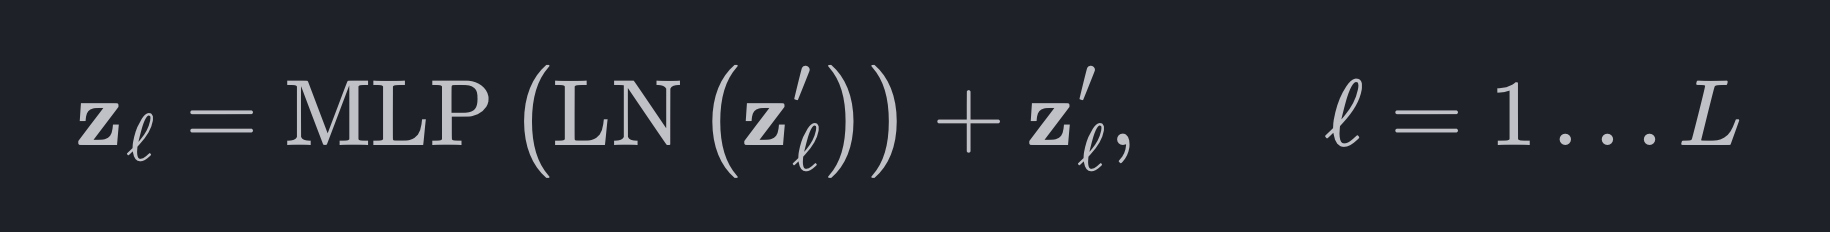

Here MLP stands for "multilayer perceptron" and LN stands for "layer normalization" (as discussed above).

And the addition on the end is the skip/residual connection.

We'll refer to equation 3 as the "MLP block" of the Transformer encoder (notice how we're continuing the trend of breaking down the architecture into smaller chunks).

### 6.1 The MLP layer(s)

The term MLP is quite broad as it can refer to almost any combination of multiple layers (hence the "multi" in multilayer perceptron).

But it generally follows the pattern of:

    * linear layer -> non-linear layer -> linear layer -> non-linear layer

In the the case of the ViT paper, the MLP structure is defined in section 3.1:

    * The MLP contains two layers with a GELU non-linearity.

Where "two layers" refers to linear layers $(torch.nn.Linear()$ in PyTorch) and "GELU non-linearity" is the GELU (Gaussian Error Linear Units) non-linear activation function $(torch.nn.GELU()$  in PyTorch).

   * Note: A linear layer (torch.nn.Linear()) can sometimes also be referred to as a "dense layer" or "feedforward layer". Some papers even use all three terms to describe the same thing (as in the ViT paper).

Another sneaky detail about the MLP block doesn't appear until Appendix B.1 (Training):

   * Table 3 summarizes our training setups for our different models. ...Dropout, when used, is applied after every dense layer except for the the qkv-projections and directly after adding positional- to patch embeddings.

This means that every linear layer (or dense layer) in the MLP block has a dropout layer $(torch.nn.Dropout()$ in PyTorch).

The value of which can be found in Table 3 of the ViT paper (for ViT-Base, dropout=0.1).

Knowing this, the structure of our MLP block will be:

    * layer norm -> linear layer -> non-linear layer -> dropout -> linear layer -> dropout

With hyperparameter values for the linear layers available from Table 1 (MLP size is the number of hidden units between the linear layers and hidden size $D$ is the output size of the MLP block).

### 6.2 Replicating Equation 3 with PyTorch layers¶
Let's put everything we've discussed about the LayerNorm (LN) and MLP (MSA) layers in equation 3 into practice.

To do so, we'll:

1. Create a class called MLPBlock that inherits from torch.nn.Module.

2. Initialize the class with hyperparameters from Table 1 and Table 3 of the ViT paper for the ViT-Base model.

3. Create a layer normalization (LN) layer with torch.nn.LayerNorm() with the normalized_shape parameter the same as our embedding dimension ($D$ from Table 1).

4. Create a sequential series of MLP layers(s) using torch.nn.Linear(), torch.nn.Dropout() and torch.nn.GELU() with appropriate hyperparameter values from Table 1 and Table 3.
5. Create a forward() method for our class passing the in the inputs through the LN layer and MLP layer(s).

In [ ]:
# 1. create a class that inherits from nn.Module
class MLPBlock(nn.Module):
  """
  Creates a lyer normalized multilayer perceptron block("MLP block"  for short).
  """
  # 2. Initialize the class with hyperparameters from Table 1 and Table 3
  def __init__(self,
               embedding_dim : int = 768, # Hidden size D from Table 1 for ViT-Base
               mlp_size : int = 3072, # MLP size from Table 1 for Vit-Base
               dropout : float = 0.1) :  # Dropout from Table 3 for Vit-Base
    super().__init__()


    # 3. Create the Norm layer (LN)
    self.layer_norm = nn.LayerNorm(normalized_shape = embedding_dim)

    # 4. Create the Multilayer perceptron (MLP) layer(s)
    self.mlp = nn.Sequential(
        nn.Linear(in_features = embedding_dim ,
                  out_features = mlp_size),
        nn.GELU(), # "The MLP contains two layers with a GELU non-linearity (section 3.1)."
        nn.Dropout(p = dropout),
        nn.Linear(in_features = mlp_size, # needs to take same in_features as out_features of layer above
                  out_features = embedding_dim),  # take back to embedding_dim
        nn.Dropout(p = dropout) # "Dropout, when used, is applied after every dense layer.."
    )

  # 5. Create a forward() method to pass the data through the layers
  def forward(self, x):
    x = self.layer_norm(x)
    x = self.mlp(x)
    return x

Note: Unlike Figure 1, our MLPBlock() doesn't include a skip or residual connection ("$+\mathbf{z}_{\ell}^{\prime}$" in equation 3), we'll include this when we create the entire Transformer encoder later on.

MLPBlock class created!

Let's try it out by create an instance of our MLPBlock and passing through the patched_image_through_msa_block variable we created in section 5.3.

In [ ]:
# create an instance of MLPBlock
mlp_block = MLPBlock(embedding_dim = 768, # from Table 1
                     mlp_size = 3072 , # from Table 1
                     dropout = 0.1 ) # from Table 3


# pass output of MSABlock through MLPBlock
patched_image_through_mlp_block = mlp_block(patched_image_through_msa_block)
print(f"Input shape of MLP Block : {patched_image_through_msa_block.shape}")
print(f"Ouput shape MLP block : {patched_image_through_mlp_block.shape}")

Input shape of MLP Block : torch.Size([1, 197, 768])
Ouput shape MLP block : torch.Size([1, 197, 768])


Notice how the input and output shape of our data again stays the same when it goes in and out of the MLP block.

However, the shape does change when the data gets passed through the nn.Linear() layers within the MLP block (expanded to MLP size from Table 1 and then compressed back to Hidden size $D$ from Table 1).

***Left:*** Vision Transformer architecture from Figure 1 with MLP and Norm layers highlighted, these layers make up equation 3 from section 3.1 of the paper.

***Right:*** Replicating equation 3 (without the skip connection on the end) using PyTorch layers.

Ho ho!

Equation 3 replicated (except for the residual connection on the end but we'll get to this in section 7.1)!

Now we've got equation's 2 and 3 in PyTorch code, let's now put them together to create the Transformer Encoder.

# 7 Create the Transformer Encode

Time to stack together our $MultiheadSelfAttentionBlock$ (equation 2) and $MLPBlock$ (equation 3) and create the Transformer Encoder of the ViT architecture.

In deep learning, an $"encoder" or "auto-encoder"$ generally refers to a stack of layers that "encodes" an input (turns it into some form of numerical representation).

In our case, the Transformer Encoder will encode our patched image embedding into a learned representation using a series of alternating layers of MSA blocks and MLP blocks, as per section 3.1 of the ViT Paper:

   * The Transformer encoder (Vaswani et al., 2017) consists of alternating layers of multiheaded selfattention (MSA, see Appendix A) and MLP blocks (Eq. 2, 3). Layernorm (LN) is applied before every block, and residual connections after every block (Wang et al., 2019; Baevski & Auli, 2019).

We've created MSA and MLP blocks but what about the residual connections?

Residual connections (also called skip connections), were first introduced in the paper Deep Residual Learning for Image Recognition and are achieved by adding a layer(s) input to its subsequent output.

Where the subsequence output might be one or more layers later.

In the case of the ViT architecture, the residual connection means the input of the MSA block is added back to the output of the MSA block before it passes to the MLP block.

And the same thing happens with the MLP block before it goes onto the next Transformer Encoder block.

Or in pseudocode:

    * x_input -> MSA_block -> [MSA_block_output + x_input] -> MLP_block -> [MLP_block_output + MSA_block_output + x_input] -> ...

What does this do?

One of the main ideas behind residual connections is that they prevent weight values and gradient updates from getting too small and thus allow deeper networks and in turn allow deeper representations to be learned.

Note: The iconic computer vision architecture "ResNet" is named so because of the introduction of residual connections. You can find many pretrained versions of ResNet architectures in torchvision.models.



### 7.1 Creating a transformer encoder by combining our custom made layers.

Enough talk, let's see this in action and make a ViT Transformer Encoder with PyTorch by combining our previously created layers.

To do so, we'll:

1. Create a class called TransformerEncoderBlock that inherits from torch.nn.Module.

2. Initialize the class with hyperparameters from Table 1 and Table 3 of the ViT paper for the ViT-Base model.

3. Instantiate a MSA block for equation 2 using our MultiheadSelfAttentionBlock from section 5.2 with the appropriate parameters.

4. Instantiate a MLP block for equation 3 using our MLPBlock from section 6.2 with the appropriate parameters.

5. Create a forward() method for our TransformerEncoderBlock class.
6. Create a residual connection for the MSA block (for equation 2).
7. Create a residual connection for the MLP block (for equation 3).

In [ ]:
# 1. Create a class that inherits from nn.Module

class TransformerEncoderBlock(nn.Module):
  # 2. Initialize the class with hyperparameters from Table 1 and table 3
  def __init__(self ,
               embedding_dim : int = 768, # Hidden size D from Table 1 for ViT-Base
               num_heads : int = 12,  # Heads from Table 1 for ViT-Base
               mlp_size : int = 3072, # MLP size from Table 1 for ViT-Base
               mlp_dropout : float = 0.1 ,  # Amount of dropout for dense layers from Table 3 for ViT-Base
               attn_dropout : float = 0) : # Amount of dropout for attention layers
    super().__init__()

    # 3. Create MSA block (equation 2 )
    self.msa_block = MultiheadSelfAttentionBlock(embedding_dim = embedding_dim,
                                                 num_heads = num_heads ,
                                                 attn_dropout = attn_dropout)

    # 4. Create MLP block (equation 3)
    self.mlp_block = MLPBlock(embedding_dim = embedding_dim ,
                              mlp_size = mlp_size ,
                              dropout = mlp_dropout)

  # 5. Create a forward() method
  def forward(self, x):

    # 6. Create residual connection for MSA block(add the input to the output )
    x = self.msa_block(x) + x

    # 7. Create residual connection for MLP block (add the input to the output)
    x  = self.mlp_block(x) + x

    return x

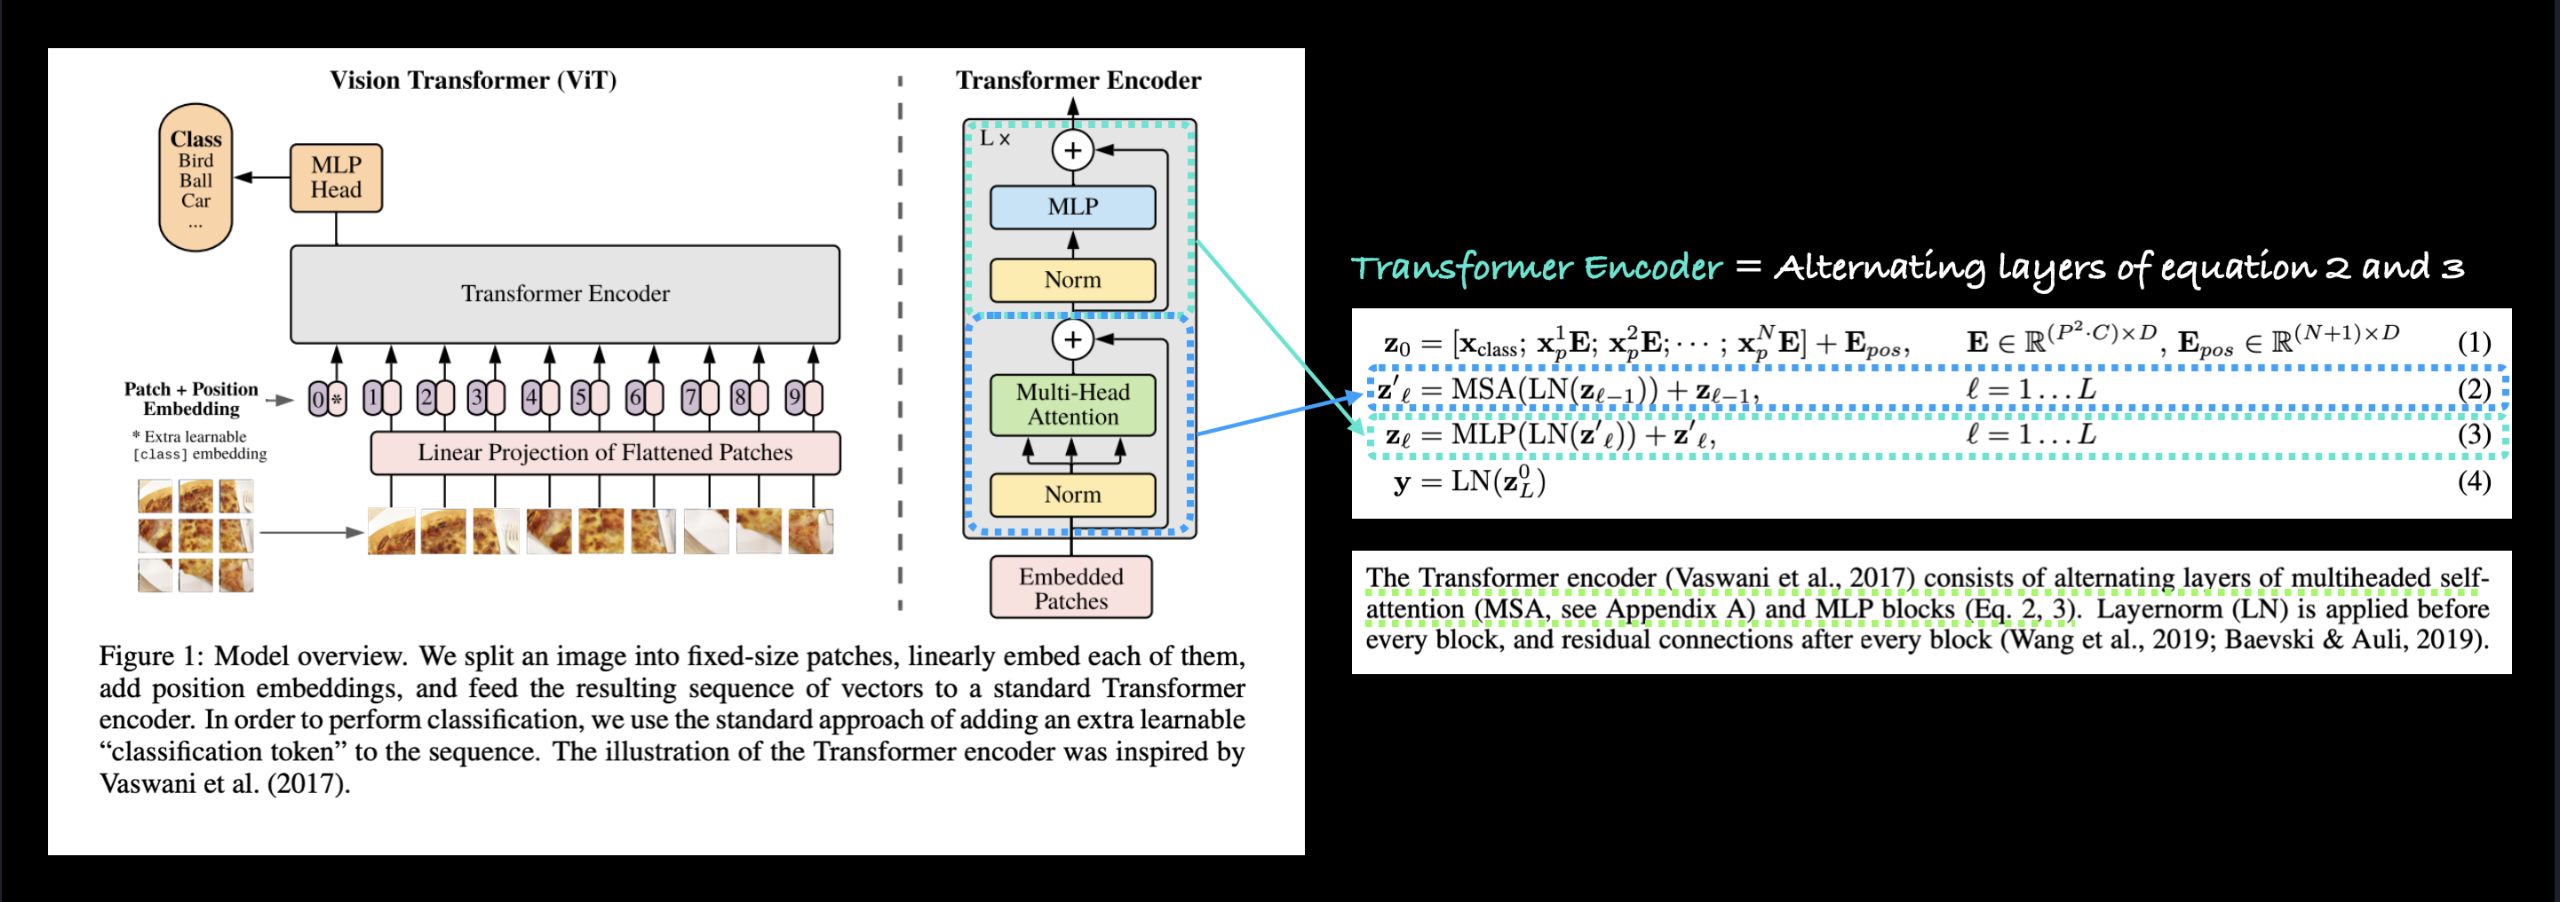

See how we're starting to piece together the overall architecture like legos, coding one brick (or equation) at a time.

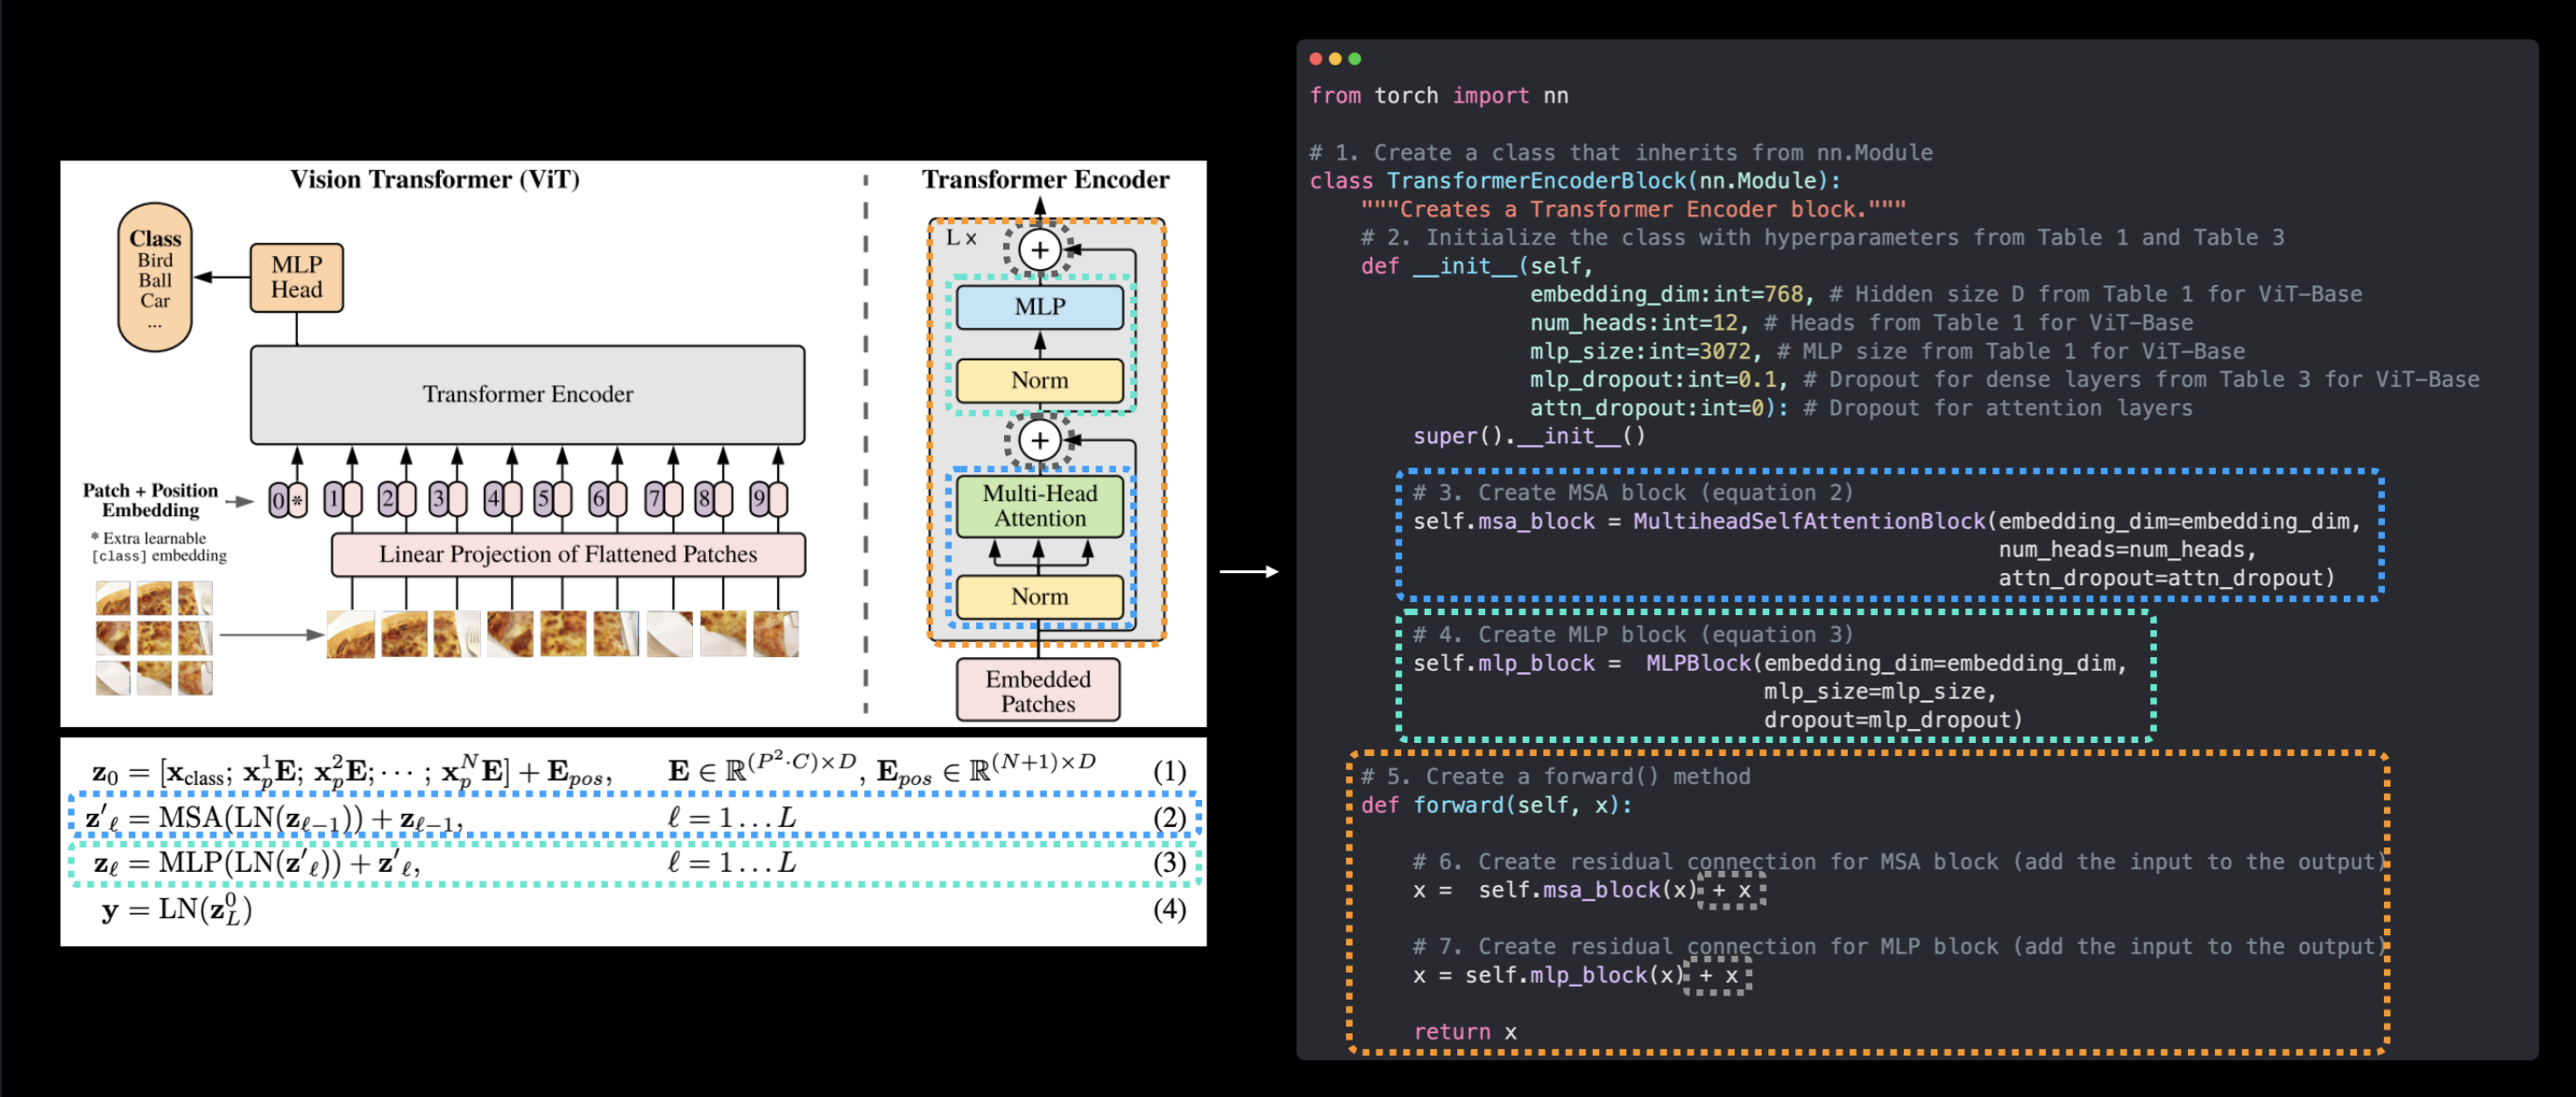

Mapping the ViT Transformer Encoder to code.

You might've noticed that Table 1 from the ViT paper has a Layers column. This refers to the number of Transformer Encoder blocks in the specific ViT architecture.

In our case, for ViT-Base, we'll be stacking together 12 of these Transformer Encoder blocks to form the backbone of our architecture (we'll get to this in section 8).

Let's get a $torchinfo.summary()$ of passing an input of shape $(1, 197, 768)$ -> (batch_size, num_patches, embedding_dimension) to our Transformer Encoder block.

In [ ]:
# create an instance oof TransformerEncoderBlock
transformer_encoder_block = TransformerEncoderBlock()

# #Print an input and output summary of our Transformer Encoder (uncomment for full output)
summary(model = transformer_encoder_block,
        input_size = (1, 197, 768), # (batch_size, num_patches, embedding_dimension)
        col_names = ["input_size" , "output_size" , "num_params" , "trainable"],
        col_width = 20 ,
        row_settings = ["var_names"])


Layer (type (var_name))                            Input Shape          Output Shape         Param #              Trainable
TransformerEncoderBlock (TransformerEncoderBlock)  [1, 197, 768]        [1, 197, 768]        --                   True
├─MultiheadSelfAttentionBlock (msa_block)          [1, 197, 768]        [1, 197, 768]        --                   True
│    └─LayerNorm (layer_norm)                      [1, 197, 768]        [1, 197, 768]        1,536                True
│    └─MultiheadAttention (multihead_attn)         --                   [1, 197, 768]        2,362,368            True
├─MLPBlock (mlp_block)                             [1, 197, 768]        [1, 197, 768]        --                   True
│    └─LayerNorm (layer_norm)                      [1, 197, 768]        [1, 197, 768]        1,536                True
│    └─Sequential (mlp)                            [1, 197, 768]        [1, 197, 768]        --                   True
│    │    └─Linear (0)                     

You can see our input changing shape as it moves through all of the various layers in the MSA block and MLP block of the Transformer Encoder block before finally returning to its original shape at the very end.

* Note: Just because our input to the Transformer Encoder block has the same shape at the output of the block doesn't mean the values weren't manipulated, the whole goal of the Transformer Encoder block (and stacking them together) is to learn a deep representation of the input using the various layers in between.

### 7.2 Creating a Transformer Encoder with PyTorch's Transformer layers
So far we've built the components of and the Transformer Encoder layer itself ourselves.

But because of their rise in popularity and effectiveness, PyTorch now has in-built Transformer layers as part of torch.nn.

For example, we can recreate the TransformerEncoderBlock we just created using torch.nn.TransformerEncoderLayer() and setting the same hyperparameters as above.

Ye section batata hai ki ab tak humne jo TransformerEncoderBlock manually banaya (custom class likhi), waisa PyTorch already provide karta hai ek built-in layer ke roop mein:

    nn.TransformerEncoderLayer()


$Kyun$: Transformers itne popular ho gaye hain ki PyTorch ne unko directly library mein add kar diya, taaki log baar-baar khud se na banayein.

Ye demonstrate kar rahe hain: Same hyperparameters (d_model=768, nhead=12, dim_feedforward=3072, dropout=0.1) use karke, tum bilkul wahi block bana sakte ho ek single line mein, jo humne pehle 3 classes (MSA + MLP + TransformerEncoderBlock) likh kar banaya tha.


In [ ]:
# Create the same as above with torch.nn.TransformerEncoderLayer()
torch_transformer_encoder_layer = nn.TransformerEncoderLayer(d_model=768, # Hidden size D from Table 1 for ViT-Base
                                                             nhead=12, # Heads from Table 1 for ViT-Base
                                                             dim_feedforward=3072, # MLP size from Table 1 for ViT-Base
                                                             dropout=0.1, # Amount of dropout for dense layers from Table 3 for ViT-Base
                                                             activation="gelu", # GELU non-linear activation
                                                             batch_first=True, # Do our batches come first?
                                                             norm_first=True) # Normalize first or after MSA/MLP layers?

torch_transformer_encoder_layer

TransformerEncoderLayer(
  (self_attn): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
  )
  (linear1): Linear(in_features=768, out_features=3072, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (linear2): Linear(in_features=3072, out_features=768, bias=True)
  (norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  (norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  (dropout1): Dropout(p=0.1, inplace=False)
  (dropout2): Dropout(p=0.1, inplace=False)
)

to inspect it further , let's get a summary with torchinfo.summary().


In [ ]:
# # Get the output of PyTorch's version of the Transformer Encoder (uncomment for full output)
summary(model = torch_transformer_encoder_layer,
       input_size = (1, 197 , 768),
       col_names = ["input_size" , "output_size" , "num_params" , "trainable"],
       col_width = 20 ,
       row_settings = ["var_names"])

Layer (type (var_name))                            Input Shape          Output Shape         Param #              Trainable
TransformerEncoderLayer (TransformerEncoderLayer)  [1, 197, 768]        [1, 197, 768]        --                   True
├─LayerNorm (norm1)                                [1, 197, 768]        [1, 197, 768]        1,536                True
├─MultiheadAttention (self_attn)                   [1, 197, 768]        [1, 197, 768]        2,362,368            True
├─Dropout (dropout1)                               [1, 197, 768]        [1, 197, 768]        --                   --
├─LayerNorm (norm2)                                [1, 197, 768]        [1, 197, 768]        1,536                True
├─Linear (linear1)                                 [1, 197, 768]        [1, 197, 3072]       2,362,368            True
├─Dropout (dropout)                                [1, 197, 3072]       [1, 197, 3072]       --                   --
├─Linear (linear2)                             

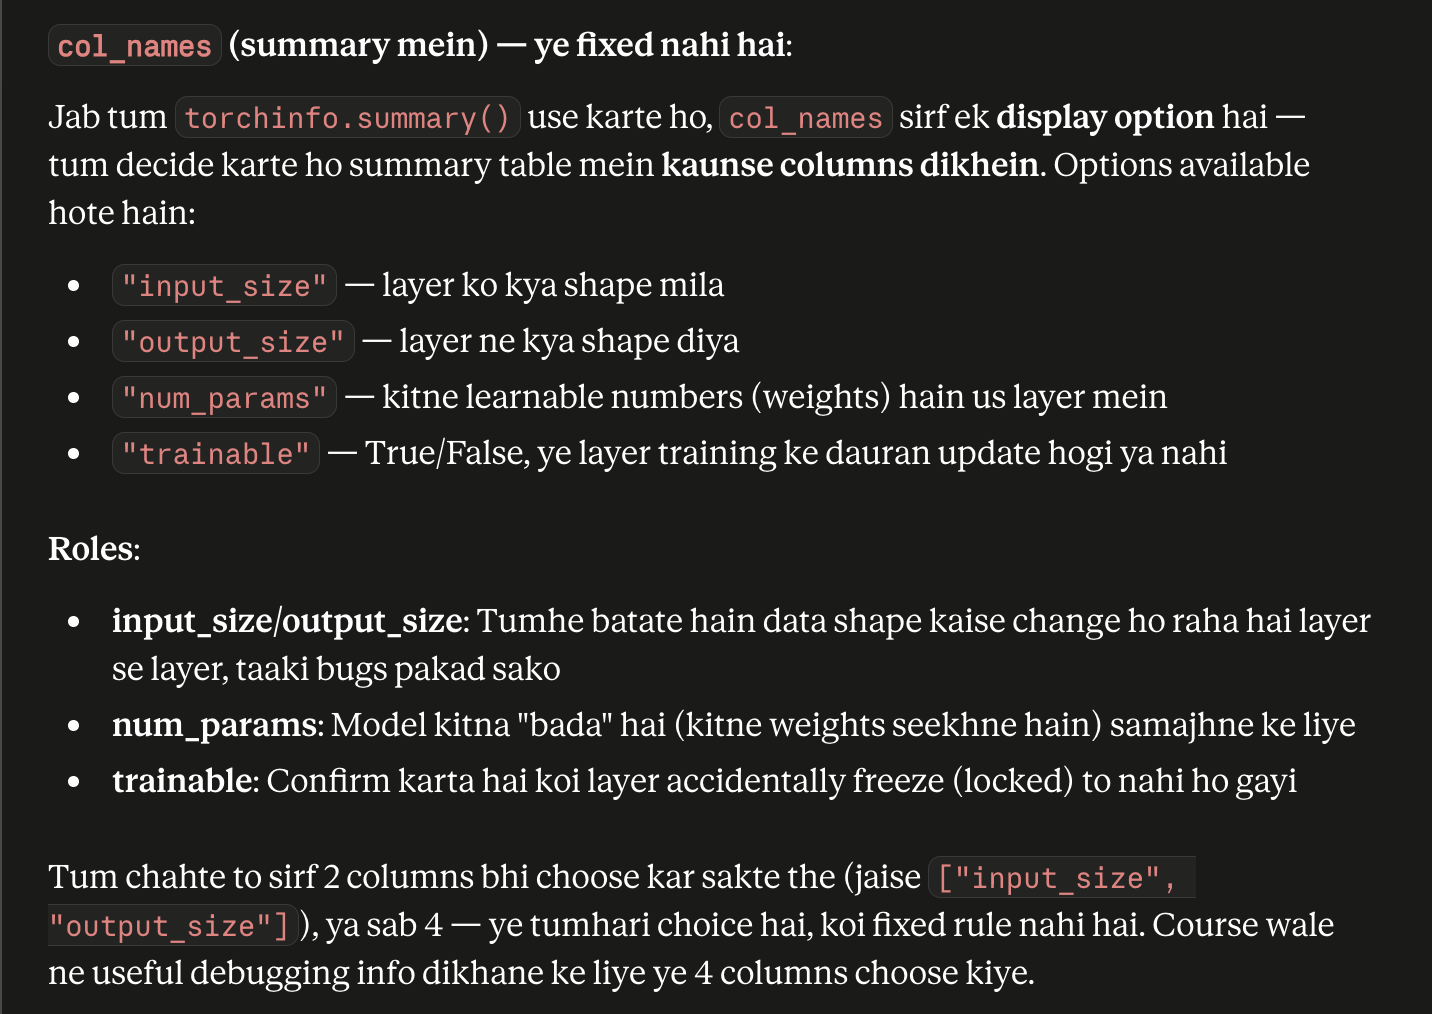

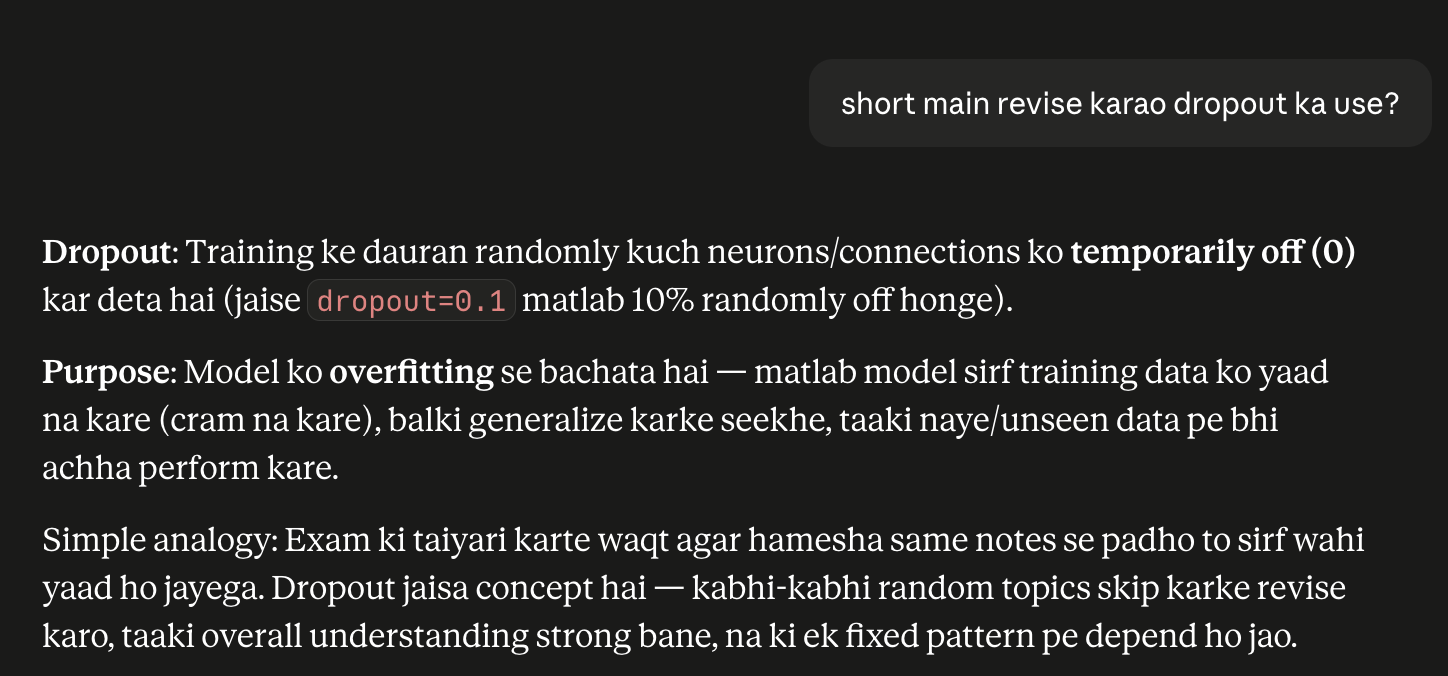

The output of the summary is slightly different to ours due to how $torch.nn.TransformerEncoderLayer()$ constructs its layer.

But the layers it uses, number of parameters and input and output shapes are the same.

You might be thinking, "if we could create the Transformer Encoder so quickly with PyTorch layers, why did we bother reproducing equation 2 and 3?"

The answer is: practice.

Now we've replicated a series of equations and layers from a paper, if you need to change the layers and try something different you can.

But there are benefits of using the PyTorch pre-built layers, such as:

* Less prone to errors - Generally, if a layer makes it into the PyTorch standard library, it's been tested and tried to work.

* Potentially better performance - As of July 2022 and PyTorch 1.12, the PyTorch implemented version of torch.nn.TransformerEncoderLayer() can see a speedup of more than 2x on many common workloads.


Finally, since the ViT architecture uses several Transformer Layers stacked on top of each for the full architecture (Table 1 shows 12 Layers in the case of ViT-Base), you can do this with torch.nn.TransformerEncoder(encoder_layer, num_layers) where:

* encoder_layer - The target Transformer Encoder layer created with torch.nn.TransformerEncoderLayer().

* num_layers - The number of Transformer Encoder layers to stack together.

# 8. Putting it all together to create ViT
We're going to combine all of the blocks we've created to replicate the full ViT architecture.

From the patch and positional embedding to the Transformer Encoder(s) to the MLP Head.

But wait, we haven't created equation 4 yet...

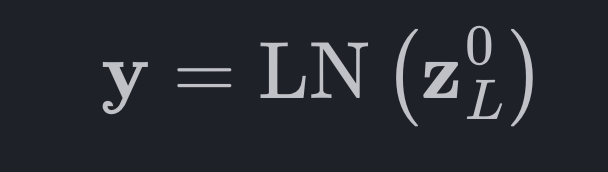

Don't worry, we can put equation 4 into our overall ViT architecture class.

All we need is a torch.nn.LayerNorm() layer and a torch.nn.Linear() layer to convert the 0th index ($\mathbf{z}_{L}^{0}$) of the Transformer Encoder logit outputs to the target number of classes we have.

To create the full architecture, we'll also need to stack a number of our TransformerEncoderBlocks on top of each other, we can do this by passing a list of them to torch.nn.Sequential() (this will make a sequential range of TransformerEncoderBlocks).

We'll focus on the ViT-Base hyperparameters from Table 1 but our code should be adaptable to other ViT variants.

Creating ViT will be our biggest code block yet but we can do it!



Finally, to bring our own implementation of ViT to life, let's:

1. Create a class called ViT that inherits from torch.nn.Module.

2. Initialize the class with hyperparameters from Table 1 and Table 3 of the ViT paper for the ViT-Base model.

3. Make sure the image size is divisible by the patch size (the image should be split into even patches).

4. Calculate the number of patches using the formula $N=H W / P^{2}$, where $H$ is the image height, $W$ is the image width and $P$ is the patch size.

5. Create a learnable class embedding token (equation 1) as done above in section 4.6.

6. Create a learnable position embedding vector (equation 1) as done above in section 4.7.

7. Setup the embedding dropout layer as discussed in Appendix B.1 of the ViT paper.

8. Create the patch embedding layer using the PatchEmbedding class as above in section 4.5.

9. Create a series of Transformer Encoder blocks by passing a list of TransformerEncoderBlocks created in section 7.1 to torch.nn.Sequential() (equations 2 & 3).

10. Create the MLP head (also called classifier head or equation 4) by passing a torch.nn.LayerNorm() (LN) layer and a torch.nn.Linear(out_features=num_classes) layer (where num_classes is the target number of classes) linear layer to torch.nn.Sequential().

11. Create a forward() method that accepts an input.

12. Get the batch size of the input (the first dimension of the shape).

13. Create the patching embedding using the layer created in step 8 (equation 1).

14. Create the class token embedding using the layer created in step 5 and expand it across the number of batches found in step 11 using torch.Tensor.expand() (equation 1).

15. Concatenate the class token embedding created in step 13 to the first dimension of the patch embedding created in step 12 using torch.cat() (equation 1).

16. Add the position embedding created in step 6 to the patch and class token embedding created in step 14 (equation 1).

17. Pass the patch and position embedding through the dropout layer created in step 7.

18. Pass the patch and position embedding from step 16 through the stack of Transformer Encoder layers created in step 9 (equations 2 & 3).

19. Pass index 0 of the output of the stack of Transformer Encoder layers from step 17 through the classifier head created in step 10 (equation 4).

20. Dance and shout woohoo!!! We just built a Vision Transformer!


In [ ]:
# 1. Create a ViT class that inherits from nn.Module
class ViT(nn.Module):
  """Creates a Vision Transformer architecture with ViT-Base hyperparameters by default."""
  # 2. Initialize the class with hyperparameters
  def __init__(self,
               img_size : int = 224, # Training resolution from Table 3 in ViT paper
               in_channels : int = 3, # Number of channels in input image
               patch_size : int = 16, # patch size
               num_transformer_layer : int = 12, # layers from table 1 for Vit-Base
               embedding_dim : int = 768, # hidden size D from yable 1 for Vit Base
               mlp_size : int = 3072 , # mlp size from table 1 for vit base
               num_heads : int = 12 , # heads from table 1 for vit base
               attn_dropout : float = 0, # dropout for attention projection
               mlp_dropout : float = 0.1, # dropout for dense/MLP layers
               embedding_dropout : float = 0.1, # dropout for patch and position embeddings
               num_classes : int = 1000): # dropout for ImageNet but can customize this
    super().__init__() # don't forget the super().__init__() 1

    # 3. make the image size is divisible by the patch size
    assert img_size % patch_size == 0, f"Image size must be divisible by patch_size, image_size : {img_size}, patch_size : {patch_size}"

    # 4. Calculate number of patches (height * width/patch^2)
    self.num_patches = (img_size * img_size) // patch_size**2
    """
    ((224 * 224) // 16^2) =>  5076 / 256 => 196
    so self.num_patches = 196
    """

    # 5. create learnable class embedding (needs to go at front of sequence of patch embedidngs )
    self.class_embedding = nn.Parameter(data = torch.randn(1 ,
                                                           1,
                                                           embedding_dim),
                                        requires_grad = True)

    # 6. Create learnable position embedding
    self.position_embedding = nn.Parameter(data = torch.randn(1,
                                                              self.num_patches+1,
                                                              embedding_dim),
                                           requires_grad = True)

    # 7. Create embedding dropout value
    self.embedidng_dropout = nn.Dropout(p = embedding_dropout)

    # 8. Create patch embedding layer
    self.patch_embedding = PatchEmbedding(in_channels = in_channels,
                                          patch_size = patch_size,
                                          embedding_dim = embedding_dim)

    # 9. create Transformer Encoder blocks (we can stack trasnformer Encoder blocks using nn.Sequential())
    # note : the "*" means "all"
    self.transformer_encoder = nn.Sequential(*[TransformerEncoderBlock(embedding_dim = embedding_dim ,
                                                                       num_heads = num_heads ,
                                                                       mlp_size = mlp_size,
                                                                       mlp_dropout = mlp_dropout) for _ in range(num_transformer_layer)])

    self.classifier = nn.Sequential(
        nn.LayerNorm(normalized_shape = embedding_dim),
        nn.Linear(in_features = embedding_dim,
                  out_features =num_classes))

  # 11. Create a forward() method
  def forward(self , x):

    # 12. Get batch size
    batch_size = x.shape[0]

    # 13. create class token embedding and expand it to match the batch size (equation 1)
    class_token = self.class_embedding.expand(batch_size , -1, -1)

    # 14. Create patch embedding (equation 1 )
    x = self.patch_embedding(x)

    # 15. concat class embedding and patch embedding (eq 1 )
    x = torch.cat((class_token, x), dim = 1 )

    # 16. add position embedding to patch embedding (eq 1)
    x = self.position_embedding + x

    # 17. Run embedidng dropout (Appendix B.1)
    x  = self.embedidng_dropout(x)

    # 18. pass patch , position and class embedding through transformer encoder  layers(eq  & 3)
    x =  self.transformer_encoder(x)

    # 19. put 0 index logit through classifier(eq 4)
    x = self.classifier(x[:, 0])
     # run on each sample in a batch at 0 index

    return x



we created layers and blocks, inputs and outputs and put them all together to build our own ViT!

Let's create a quick demo to showcase what's happening with the class token embedding being expanded over the batch dimensions.



for below code - Ye ek small demo/test hai — sirf ye dikhane ke liye ki class token batch size ke saath kaise expand hota hai (ye real ViT class ka part nahi, sirf samajhne ke liye alag se example hai).


Note:- Key Points:

1. Single image ke liye class token shape hota hai [1, 1, 768] → (1 image, 1 token, 768 embedding_dim)

2. Real training mein images batches mein process hoti hain (jaise 32 images ek saath), so har image ko apna class token chahiye

3. .expand(batch_size, -1, -1) class token ko copy/repeat karta hai batch size jitna baar

4. -1 matlab: "ye dimension change mat karo, jaisa hai waisa rakho"

5. Result: [1, 1, 768] → [32, 1, 768] (batch dimension 1 se 32 hua, baaki same rahe)

6. Ye same learnable values sabhi images ke liye share hoti hain (naya parameter nahi banta, sirf shape expand hoti hai)

7. Purpose: Batch processing ke liye class token ko har image ke saath align karna, taaki har image apna alag class token pa sake (structurally), lekin values initially same rehti hain.

In [ ]:
#example of creating the class embedding and expanding over a batch dimension
batch_size = 32
class_token_embedding_single = nn.Parameter(data = torch.randn(1, 1, 768))
class_token_embedding_expanded = class_token_embedding_single.expand(batch_size, -1, -1)# expand the single learnable class token across the batch dimension, "-1" means to "infer the dimension."

# print out the change in shapes
print(f"shape of the class token embedding single : {class_token_embedding_single.shape}")
print(f"shape of the class token embedding expanded : {class_token_embedding_expanded.shape}")


shape of the class token embedding single : torch.Size([1, 1, 768])
shape of the class token embedding expanded : torch.Size([32, 1, 768])


Notice how the first dimension gets expanded to the batch size and the other dimensions stay the same (because they're inferred by the "-1" dimensions in .expand(batch_size, -1, -1)).

Alright time to test out ViT() class.

Let's create a random tensor in the same shape as a single image, pass to an instance of ViT and see what happens.

In [ ]:
set_seeds()

# create a random tensor with same shape as a single image
random_image_tensor = torch.randn(1,3, 224, 224) # (batch_size , color_channels, height , width)

# create an instane of ViT with the no. of classes we're working with (Pizza , steak, sushi)
vit = ViT(num_classes = len(class_names))

# pass the random image tensor to out ViT instance
vit(random_image_tensor)

tensor([[0.2525, 0.8748, 1.2374]], grad_fn=<AddmmBackward0>)

it looks like our random image tensor made it all the way through our ViT architecture and it's outputting three logit values (one for each class).

And because our ViT class has plenty of parameters we could customize the img_size, patch_size or num_classes if we wanted to.

### 8.1 Getting a visual summary of our ViT model
We handcrafted our own version of the ViT architecture and seen that a random image tensor can flow all the way through it.

How about we use torchinfo.summary() to get a visual overview of the input and output shapes of all the layers in our model?

Note: The ViT paper states the use of a batch size of 4096 for training, however, this requires a far bit of CPU/GPU compute memory to handle (the larger the batch size the more memory required). So to make sure we don't get memory errors, we'll stick with a batch size of 32. You could always increase this later if you have access to hardware with more memory.

In [ ]:
from torchinfo import summary
# # Print a summary of our custom ViT model using torchinfo (uncomment for actual output)
summary(model = vit,
        input_size = (32, 3, 224, 224),
        col_names = ["input_size" , "output_size" , "num_params" , "trainable"],
        col_width = 20,
        row_settings = ["var_names"]
        )

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
ViT (ViT)                                                    [32, 3, 224, 224]    [32, 3]              152,064              True
├─PatchEmbedding (patch_embedding)                           [32, 3, 224, 224]    [32, 196, 768]       --                   True
│    └─Conv2d (patcher)                                      [32, 3, 224, 224]    [32, 768, 14, 14]    590,592              True
│    └─Flatten (flatten)                                     [32, 768, 14, 14]    [32, 768, 196]       --                   --
├─Dropout (embedidng_dropout)                                [32, 197, 768]       [32, 197, 768]       --                   --
├─Sequential (transformer_encoder)                           [32, 197, 768]       [32, 197, 768]       --                   True
│    └─TransformerEncoderBlock (0)                           [32, 197, 768]       [32, 197, 768]

Now those are some nice looking layers!

Checkout the total number of parameters too, 85,800,963, our biggest model yet!

The number is very close to PyTorch's pretrained ViT-Base with patch size 16 at torch.vision.models.vit_b_16() with 86,567,656 total parameters (though this number of parameters is for the 1000 classes in ImageNet).

Exercise: Try changing the num_classes parameter of our ViT() model to 1000 and then creating another summary with torchinfo.summary() and see if the number of parameters lines up between our code and torchvision.models.vit_b_16().

# 9. Setting up training code for our ViT model

we've got most of what we need ready to go, from our model (vit) to our DataLoaders (train_dataloader, test_dataloader) to the training functions we created in 05. PyTorch Going Modular section 4.

To train our model we can import the train() function from going_modular.going_modular.engine.

All we need is a loss function and an optimizer

### 9.1 Creating an optimizer
Searching the ViT paper for "optimizer", section 4.1 on Training & Fine-tuning states:

   * Training & Fine-tuning. We train all models, including ResNets, using Adam (Kingma & Ba, 2015 ) with $\beta_{1}=0.9, \beta_{2}=0.999$, a batch size of 4096 and apply a high weight decay of $0.1$, which we found to be useful for transfer of all models (Appendix D.1 shows that, in contrast to common practices, Adam works slightly better than SGD for ResNets in our setting).

So we can see they chose to use the "Adam" optimizer (torch.optim.Adam()) rather than SGD (stochastic gradient descent, torch.optim.SGD()).

The authors set Adam's $\beta$ (beta) values to $\beta_{1}=0.9, \beta_{2}=0.999$, these are the default values for the betas parameter in torch.optim.Adam(betas=(0.9, 0.999)).

They also state the use of weight decay (slowly reducing the values of the weights during optimization to prevent overfitting), we can set this with the weight_decay parameter in torch.optim.Adam(weight_decay=0.3) (according to the setting of ViT-* trained on ImageNet-1k).

We'll set the learning rate of the optimizer to 0.003 as per Table 3 (according to the setting of ViT-* trained on ImageNet-1k).

And as discussed previously, we're going to use a lower batch size than 4096 due to hardware limitations (if you have a large GPU, feel free to increase this).

### 9.2 Creating a loss function
Strangely, searching the ViT paper for "loss" or "loss function" or "criterion" returns no results.

However, since the target problem we're working with is multi-class classification (the same for the ViT paper), we'll use torch.nn.CrossEntropyLoss().

### 9.3 Training our ViT model
Okay, now we know what optimizer and loss function we're going to use, let's setup the training code for training our ViT.

We'll start by importing the engine.py script from going_modular.going_modular then we'll setup the optimizer and loss function and finally we'll use the train() function from engine.py to train our ViT model for 10 epochs (we're using a smaller number of epochs than the ViT paper to make sure everything works).

In [ ]:
# setup the optimzier to optimize our ViT model parameters using hyperparameters from the ViT paper
optimizer = torch.optim.Adam(params = vit.parameters(),
                             lr = 3e-3,
                             betas = (0.9, 0.999),
                             weight_decay = 0.3)
# setup the loss function for multi-class classification
loss_fn = torch.nn.CrossEntropyLoss()

# set the seeds
set_seeds()

# train the model and save the trainaing results to dictionary
results = engine.train(model = vit ,
                       train_dataloader = train_dataloader,
                       test_dataloader = test_dataloader,
                       optimizer = optimizer ,
                       loss_fn = loss_fn ,
                       epochs = 5 ,
                       device =device)

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 5.1949 | train_acc: 0.3633 | test_loss: 5.1213 | test_acc: 0.2604
Epoch: 2 | train_loss: 1.9517 | train_acc: 0.3320 | test_loss: 1.6205 | test_acc: 0.2604
Epoch: 3 | train_loss: 1.2073 | train_acc: 0.4570 | test_loss: 1.7585 | test_acc: 0.2604
Epoch: 4 | train_loss: 1.2482 | train_acc: 0.2969 | test_loss: 1.3214 | test_acc: 0.1979
Epoch: 5 | train_loss: 1.1331 | train_acc: 0.4297 | test_loss: 1.2293 | test_acc: 0.2604


### 9.4 What our training setup is missing
The original ViT architecture achieves good results on several image classification benchmarks (on par or better than many state-of-the-art results when it was released).

However, our results (so far) aren't as good.

There's a few reasons this could be but the main one is scale.

The original ViT paper uses a far larger amount of data than ours (in deep learning, more data is generally always a good thing) and a longer training schedule (see Table 3).

### 9.4 What our training setup is missing
The original ViT architecture achieves good results on several image classification benchmarks (on par or better than many state-of-the-art results when it was released).

However, our results (so far) aren't as good.

There's a few reasons this could be but the main one is scale.

The original ViT paper uses a far larger amount of data than ours (in deep learning, more data is generally always a good thing) and a longer training schedule (see Table 3).



Even though our ViT architecture is the same as the paper, the results from the ViT paper were achieved using far more data and a more elaborate training scheme than ours.

Because of the size of the ViT architecture and its high number of parameters (increased learning capabilities), and amount of data it uses (increased learning opportunities), many of the techniques used in the ViT paper training scheme such as learning rate warmup, learning rate decay and gradient clipping are specifically designed to prevent overfitting (regularization).

   * Note: For any technique you're unsure of, you can often quickly find an example by searching "pytorch TECHNIQUE NAME", for exmaple, say you wanted to learn about learning rate warmup and what it does, you could search "pytorch learning rate warmup".

Good news is, there are many pretrained ViT models (using vast amounts of data) available online, we'll see one in action in section 10.

### 9.5 Plot the loss curves of our ViT model
We've trained our ViT model and seen the results as numbers on a page.

But let's now follow the data explorer's motto of visualize, visualize, visualize!

And one of the best things to visualize for a model is its loss curves.

To check out our ViT model's loss curves, we can use the plot_loss_curves function from helper_functions.py we created in 04. PyTorch Custom Datasets section 7.8.

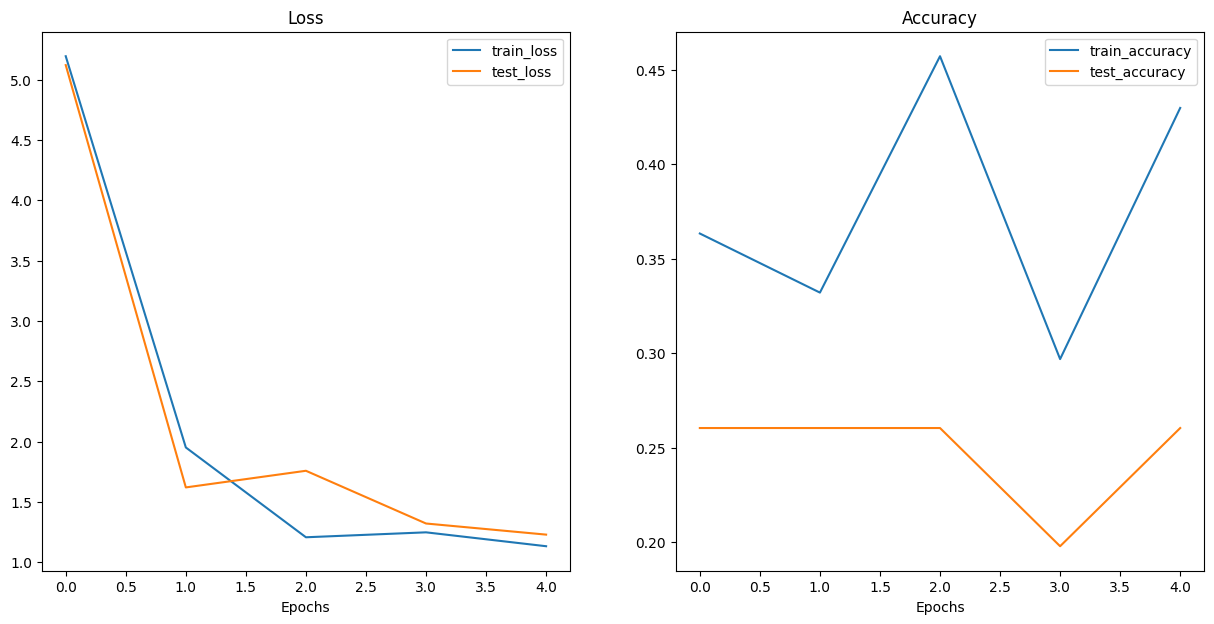

In [ ]:
# plot our ViT model's loss curves
plot_loss_curves(results)

Hmm, it looks like our model's loss curves are all over the place.

At least the loss looks like it's heading the right direction but the accuracy curves don't really show much promise.

These results are likely because of the difference in data resources and training regime of our ViT model versus the ViT paper.

It seems our model is severely underfitting (not achieving the results we'd like it to).

How about we see if we can fix that by bringing in a pretrained ViT model?

# 10. Using a pretrained ViT from torchvision.models on the same dataset
We've discussed the benefits of using pretrained models in 06. PyTorch Transfer Learning.

But since we've now trained our own ViT from scratch and achieved less than optimal results, the benefits of transfer learning (using a pretrained model) really shine.

### 10.1 Why use a pretrained model?
An important note on many modern machine learning research papers is that much of the results are obtained with large datasets and vast compute resources.

And in modern day machine learning, the original fully trained ViT would likely not be considered a "super large" training setup (models are continually getting bigger and bigger).

Reading the ViT paper section 4.2:

   * Finally, the ViT-L/16 model pre-trained on the public ImageNet-21k dataset performs well on most datasets too, while taking fewer resources to pre-train: it could be trained using a standard cloud TPUv3 with 8 cores in approximately 30 days.

As of July 2022, the price for renting a TPUv3 (Tensor Processing Unit version 3) with 8 cores on Google Cloud is $8 USD per hour.

To rent one for 30 straight days would cost $5,760 USD.

This cost (monetary and time) may be viable for some larger research teams or enterprises but for many people it's not.

So having a pretrained model available through resources like torchvision.models, the timm (Torch Image Models) library, the HuggingFace Hub or even from the authors of the papers themselves (there's a growing trend for machine learning researchers to release the code and pretrained models from their research papers, I'm a big fan of this trend, many of these resources can be found on Paperswithcode.com).

If you're focused on leveraging the benefits of a specific model architecture rather than creating your custom architecture, I'd highly recommend using a pretrained model.

### 10.2 Getting a pretrained ViT model and creating a feature extractor
We can get a pretrained ViT model from torchvision.models.

We'll go from the top by first making sure we've got the right versions of torch and torchvision.


In [ ]:
import torch
import torchvision
print(torch.__version__)
print(torchvision.__version__)

2.11.0+cu128
0.26.0+cu128


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'


Finally, we'll get the pretrained ViT-Base with patch size 16 from torchvision.models and prepare it for our FoodVision Mini use case by turning it into a feature extractor transfer learning model.

Specifically, we'll:

1. Get the pretrained weights for ViT-Base trained on ImageNet-1k from torchvision.models.ViT_B_16_Weights.DEFAULT (DEFAULT stands for best available).

2. Setup a ViT model instance via torchvision.models.vit_b_16, pass it the pretrained weights step 1 and send it to the target device.

3. Freeze all of the parameters in the base ViT model created in step 2 by setting their requires_grad attribute to False.

4. Update the classifier head of the ViT model created in step 2 to suit our own problem by changing the number of out_features to our number of classes (pizza, steak, sushi).


  * We covered steps like this in 06. PyTorch Transfer Learning section 3.2: Setting up a pretrained model and section 3.4: Freezing the base model and changing the output layer to suit our needs.

In [ ]:
# 1. Get pretrianed weights for ViT-Base
pretrained_vit_weights = torchvision.models.ViT_B_16_Weights.DEFAULT
# 2. Setup a Vit model instance with pretrained weights
pretrained_vit = torchvision.models.vit_b_16(weights = pretrained_vit_weights).to(device)

# 3. Freeze the base parameters
for parameter in pretrained_vit.parameters():
  parameter.requires_grad = False

# 4. Change the classifier head(se the seeds to ensure same initialization with linear head)
set_seeds()
pretrained_vit.heads = nn.Linear(in_features = 768 , out_features = len(class_names)).to(device)
# pretrained_vit # uncomment for model output


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 186MB/s]


#### TBR

.DEFAULT matlab: torchvision ko batao "sabse best/latest recommended pretrained weights de do" (automatically select karta hai). Iske bina, weights load hi nahi honge — .DEFAULT zaroori hai.

In [ ]:
# # Print a summary using torchinfo (uncomment for actual output)
summary(model = pretrained_vit,
        input_size = (32 , 3, 224, 224),
        col_names = ["input_size" , "output_size" , "num_params" , "trainable"],
        col_width = 20 ,
        row_settings = ["var_names"]
        )


Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
VisionTransformer (VisionTransformer)                        [32, 3, 224, 224]    [32, 3]              768                  Partial
├─Conv2d (conv_proj)                                         [32, 3, 224, 224]    [32, 768, 14, 14]    (590,592)            False
├─Encoder (encoder)                                          [32, 197, 768]       [32, 197, 768]       151,296              False
│    └─Dropout (dropout)                                     [32, 197, 768]       [32, 197, 768]       --                   --
│    └─Sequential (layers)                                   [32, 197, 768]       [32, 197, 768]       --                   False
│    │    └─EncoderBlock (encoder_layer_0)                   [32, 197, 768]       [32, 197, 768]       (7,087,872)          False
│    │    └─EncoderBlock (encoder_layer_1)                   [32, 197, 768]       [32, 

Notice how only the output layer is trainable, where as, all of the rest of the layers are untrainable (frozen).

And the total number of parameters, 85,800,963, is the same as our custom made ViT model above.

But the number of trainable parameters for pretrained_vit is much, much lower than our custom vit at only 2,307 compared to 85,800,963 (in our custom vit, since we're training from scratch, all parameters are trainable).

This means the pretrained model should train a lot faster, we could potentially even use a larger batch size since less parameter updates are going to be taking up memory.

### 10.3 Preparing data for the pretrained ViT model
We downloaded and created DataLoaders for our own ViT model back in section 2.

So we don't necessarily need to do it again.

But in the name of practice, let's download some image data (pizza, steak and sushi images for Food Vision Mini), setup train and test directories and then transform the images into tensors and DataLoaders.

We can download pizza, steak and sushi images from the course GitHub and the download_data() function we created in 07. PyTorch Experiment Tracking section 1.

In [ ]:
from helper_functions import download_data

# Download pizza, steak, sushi images from GitHub
image_path = download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip",
                           destination="pizza_steak_sushi")
image_path

[INFO] data/pizza_steak_sushi directory exists, skipping download.


PosixPath('data/pizza_steak_sushi')

In [ ]:
# setup train and tes directory paths
train_dir = image_path / "train"
test_dir = image_path / "test"
train_dir , test_dir

(PosixPath('data/pizza_steak_sushi/train'),
 PosixPath('data/pizza_steak_sushi/test'))


Finally, we'll transform our images into tensors and turn the tensors into DataLoaders.

Since we're using a pretrained model from torchvision.models we can call the transforms() method on it to get its required transforms.

Remember, if you're going to use a pretrained model, it's generally important to ensure your own custom data is transformed/formatted in the same way the data the original model was trained on.

We covered this method of "automatic" transform creation in 06. PyTorch Transfer Learning section 2.2.

In [ ]:
# get automatic transforms from pretrianed ViT weights
pretrained_vit_transforms = pretrained_vit_weights.transforms()
print(pretrained_vit_transforms)

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


And now we've got transforms ready, we can turn our images into DataLoaders using the data_setup.create_dataloaders() method we created in 05. PyTorch Going Modular section 2.

Since we're using a feature extractor model (less trainable parameters), we could increase the batch size to a higher value (if we set it to 1024, we'd be mimicking an improvement found in Better plain ViT baselines for ImageNet-1k, a paper which improves upon the original ViT paper and suggested extra reading). But since we only have ~200 training samples total, we'll stick with 32.

In [ ]:
# setup dataloaders
train_dataloader_pretrained ,test_dataloader_pretrained , class_names = data_setup.create_dataloaders(train_dir = train_dir ,
                                                                                                      test_dir = test_dir ,
                                                                                                      transform = pretrained_vit_transforms,
                                                                                                      batch_size = 32) # could increase if we had more samples , such as

# could increase if we had more samples , such as here :

 * https://arxiv.org/abs/2205.01580

(there are other improvements there too..)

### 10.4 Train feature extractor ViT model

Feature extractor model ready, DataLoaders ready, time to train!

As before we'll use the Adam optimizer (torch.optim.Adam()) with a learning rate of 1e-3 and torch.nn.CrossEntropyLoss() as the loss function.

Our engine.train() function we created in 05. PyTorch Going Modular section 4 will take care of the rest.



In [ ]:
# create optimizer and loss function
optimizer = torch.optim.Adam(params = pretrained_vit.parameters(),
                             lr = 1e-3)
loss_fn = torch.nn.CrossEntropyLoss()

# train the classifier head of the pretrained ViT feature extractor model
set_seeds()
pretrained_vit_results = engine.train(model = pretrained_vit,
                                      train_dataloader = train_dataloader,
                                      test_dataloader = test_dataloader ,
                                      optimizer = optimizer ,
                                      loss_fn = loss_fn ,
                                      device = device,
                                      epochs = 10)


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 0.8333 | train_acc: 0.6484 | test_loss: 0.6476 | test_acc: 0.9072
Epoch: 2 | train_loss: 0.4814 | train_acc: 0.8867 | test_loss: 0.4171 | test_acc: 0.9384
Epoch: 3 | train_loss: 0.3158 | train_acc: 0.9414 | test_loss: 0.3284 | test_acc: 0.9384
Epoch: 4 | train_loss: 0.2510 | train_acc: 0.9531 | test_loss: 0.2648 | test_acc: 0.9688
Epoch: 5 | train_loss: 0.1998 | train_acc: 0.9531 | test_loss: 0.2421 | test_acc: 0.9384
Epoch: 6 | train_loss: 0.1812 | train_acc: 0.9609 | test_loss: 0.2161 | test_acc: 0.9384
Epoch: 7 | train_loss: 0.1670 | train_acc: 0.9609 | test_loss: 0.2154 | test_acc: 0.9384
Epoch: 8 | train_loss: 0.1422 | train_acc: 0.9648 | test_loss: 0.2146 | test_acc: 0.9384
Epoch: 9 | train_loss: 0.1879 | train_acc: 0.9766 | test_loss: 0.1890 | test_acc: 0.9384
Epoch: 10 | train_loss: 0.1341 | train_acc: 0.9570 | test_loss: 0.1774 | test_acc: 0.9583


Looks like our pretrained ViT feature extractor performed far better than our custom ViT model trained from scratch (in the same amount of time).

Let's get visual.

### 10.5 Plot feature extractor ViT model loss curves¶
Our pretrained ViT feature model numbers look good on the training and test sets.

How do the loss curves look?

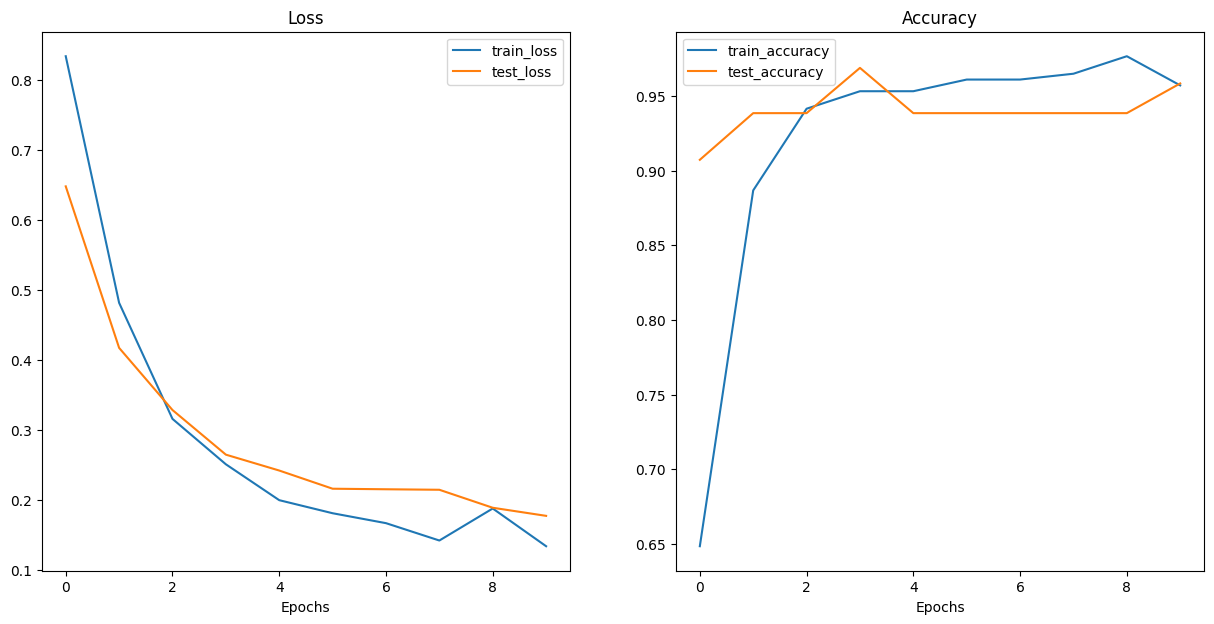

In [ ]:
# plot the loss curves
from helper_functions import plot_loss_curves

plot_loss_curves(pretrained_vit_results)

Those are some close to textbook looking (really good) loss curves (check out 04. PyTorch Custom Datasets section 8 for what an ideal loss curve should look like).

That's the power of transfer learning!

We managed to get outstanding results with the same model architecture, except our custom implementation was trained from scratch (worse performance) and this feature extractor model has the power of pretrained weights from ImageNet behind it.

What do you think?

Would our feature extractor model improve more if you kept training it?

### 10.6 Save feature extractor ViT model and check file size

It looks like our ViT feature extractor model is performing quite well for our Food Vision Mini problem.

Perhaps we might want to try deploying it and see how it goes in production (in this case, deploying means putting our trained model in an application someone could use, say taking photos on their smartphone of food and seeing if our model thinks it's pizza, steak or sushi).

To do so we can first save our model with the utils.save_model() function we created in 05. PyTorch Going Modular section 5.

In [ ]:
# save the model
from going_modular.going_modular import utils

utils.save_model(model = pretrained_vit ,
                 target_dir = "models",
                 model_name = "08_pretrained_vit_feature_extractor_pizza_steak_sushi.pth")


[INFO] Saving model to: models/08_pretrained_vit_feature_extractor_pizza_steak_sushi.pth


And since we're thinking about deploying this model, it'd be good to know the size of it (in megabytes or MB).

Since we want our Food Vision Mini application to run fast, generally a smaller model with good performance will be better than a larger model with great performance.

We can check the size of our model in bytes using the st_size attribute of Python's pathlib.Path().stat() method whilst passing it our model's filepath name.

We can then scale the size in bytes to megabytes

In [ ]:
from pathlib import Path

# Get the model size in bytes then convert to megabytes
pretrained_vit_model_size = Path("models/08_pretrained_vit_feature_extractor_pizza_steak_sushi.pth").stat().st_size // (1024*1024) # division converts bytes to megabytes (roughly)
print(f"Pretrained ViT feature extractor model size: {pretrained_vit_model_size} MB")

Pretrained ViT feature extractor model size: 327 MB


Note: ^ the EffNetB2 model in reference was trained with 20% of pizza, steak and sushi data (double the amount of images) rather than the ViT feature extractor which was trained with 10% of pizza, steak and sushi data. An exercise would be to train the ViT feature extractor model on the same amount of data and see how much the results improve.

The EffNetB2 model is ~11x smaller than the ViT model with similar results for test loss and accuracy.

However, the ViT model's results may improve more when trained with the same data (20% pizza, steak and sushi data).

But in terms of deployment, if we were comparing these two models, something we'd need to consider is whether the extra accuracy from the ViT model is worth the ~11x increase in model size?

Perhaps such a large model would take longer to load/run and wouldn't provide as good an experience as EffNetB2 which performs similarly but at a much reduced size.

# 11. Make predictions on a custom image

And finally, we'll finish with the ultimate test, predicting on our own custom data.

Let's download the pizza dad image (a photo of my dad eating pizza) and use our ViT feature extractor to predict on it.

To do so, let's use the pred_and_plot() function we created in 06. PyTorch Transfer Learning section 6, for convenience, I saved this function to going_modular.going_modular.predictions.py on the course GitHub.

In [ ]:
import requests

# Import function to make predictions on images and plot them
from going_modular.going_modular.predictions import pred_and_plot_image

# Setup custom image path
custom_image_path = image_path / "04-pizza-dad.jpeg"

# Download the image if it doesn't already exist
if not custom_image_path.is_file():
    with open(custom_image_path, "wb") as f:
        # When downloading from GitHub, need to use the "raw" file link
        request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/04-pizza-dad.jpeg")
        print(f"Downloading {custom_image_path}...")
        f.write(request.content)
else:
    print(f"{custom_image_path} already exists, skipping download.")

# Predict on custom image
pred_and_plot_image(model=pretrained_vit,
                    image_path=custom_image_path,
                    class_names=class_names)

# Main takeaways

* With the explosion of machine learning, new research papers detailing advancements come out every day. And it's impossible to keep up with it all but you can narrow things down to your own use case, such as what we did here, replicating a computer vision paper for FoodVision Mini.

* Machine learning research papers often contain months of research by teams of smart people compressed into a few pages (so teasing out all the details and replicating the paper in full can be a bit of challenge).

* The goal of paper replicating is to turn machine learning research papers (text and math) into usable code.
   * With this being said, many machine learning research teams are starting to publish code with their papers and one of the best places to see this is at Paperswithcode.com

* Breaking a machine learning research paper into inputs and outputs (what goes in and out of each layer/block/model?) and layers (how does each layer manipulate the input?) and blocks (a collection of layers) and replicating each part step by step (like we've done in this notebook) can be very helpful for understanding.

* Pretrained models are available for many state of the art model architectures and with the power of transfer learning, these often perform very well with little data.

* Larger models generally perform better but have a larger footprint too (they take up more storage space and can take longer to perform inference).

   * A big question is: deployment wise, is the extra performance of a larger model worth it/aligned with the use case?

In [ ]:
print("chao")

chao
